# SDS Mini Datathon 2026: Submission Notebook

**Team name:** Mixue lovers

**Members:** Xiong Zirui, Lee Juin Hsien Justin, Chew Zhan Shi Jordan

---

### Before you start
- Keep every section heading below, in this order. You may add cells and sub-headings inside each section.
- This notebook must run on **Python 3.14** using **Restart & Run All**, with no errors, in under **10 minutes**.
- Every chart in your deck must be generated in this notebook.
- Load data from the `data/` folder using relative paths only. Do not load data live from a website or API.
- Delete these instruction cells (the ones starting with *Instructions*) before submitting if you like, but keep the headings.

### Before you submit
1. Kernel → **Restart & Run All**, and check there are no errors.
2. Save the notebook with all outputs.
3. Export it as `main.html` (File → Save and Export Notebook As → HTML).
4. Zip the `TeamName/` folder: `main.ipynb`, `main.html`, `requirements.txt`, `deck.pdf`, `data/`.

## 1. Setup & Imports

*Instructions:* Import every library you use here. Each one must be listed, with its exact version, in `requirements.txt`.

In [1]:
import sys
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
# Python version check: the judges' environment uses Python 3.14
print(f"Python version: {sys.version.split()[0]}")
if sys.version_info[:2] != (3, 14):
    print("WARNING: this notebook will be run on Python 3.14. Please test it on 3.14 before submitting.")

Python version: 3.14.6


In [3]:
# Random seed: keep this so your results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
# If you use other libraries with randomness, set their seeds too,
# e.g. random_state=SEED in scikit-learn models

In [4]:
# Display settings (optional)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Data Ingestion

*Instructions:* Load all data from the `data/` folder using relative paths. If you use any additional public datasets, download them into `data/` and cite them in Section 9.

In [5]:
# Provided datasets (update the file names if needed)
coe_raw = pd.read_csv("data/COEBiddingResultsPrices.csv")
registrations_raw = pd.read_csv("data/NewRegistrationofCarsbyMake.csv")

print(f"COE bidding data: {coe_raw.shape[0]:,} rows, {coe_raw.shape[1]} columns")
print(f"Registration data: {registrations_raw.shape[0]:,} rows, {registrations_raw.shape[1]} columns")

COE bidding data: 1,990 rows, 7 columns
Registration data: 51,669 rows, 6 columns


In [6]:
coe_raw.head()

,month,bidding_no,vehicle_class,quota,bids_success,bids_received,premium
0,2010-01,1,Category A,1152,1145,1342,18502
1,2010-01,1,Category B,687,679,883,19190
2,2010-01,1,Category C,173,173,265,19001
3,2010-01,1,Category D,373,365,509,889
4,2010-01,1,Category E,586,567,1011,19889


In [7]:
registrations_raw.head()

,month,make,importer_type,fuel_type,vehicle_type,number
0,2016-01,ALFA ROMEO,NaN,Petrol,Hatchback,3.0
1,2016-01,ALPINA,NaN,Petrol,Hatchback,0.0
2,2016-01,ASTON MARTIN,NaN,Petrol,Hatchback,0.0
3,2016-01,AUDI,NaN,Petrol,Hatchback,45.0
4,2016-01,B.M.W.,NaN,Petrol,Hatchback,5.0


## 3. Data Cleaning

*Instructions:* Show every cleaning step, with a short note on why. For example: fixing data types, handling missing values, removing duplicates, and aggregating registrations to monthly totals before joining with the COE data.

**Reminder:** the two datasets overlap from January 2016 to May 2025.

### 3.1 COE Dataframe

In [8]:
# split month into year and month
coe_raw[['year', 'month']] = coe_raw['month'].str.split('-', expand=True)
coe_raw['year'] = coe_raw['year'].astype(int)
coe_raw['month'] = coe_raw['month'].astype(int)
col = coe_raw.pop("year")
coe_raw.insert(0, "year", col)

# Create monthly date variable
coe_raw["date"] = pd.to_datetime(
    coe_raw[["year", "month"]].assign(day=1)
)

# change to int
cols = ["bids_received", "bids_success"]
coe_raw[cols] = coe_raw[cols].apply(
    lambda col: col.astype(str).str.replace(",", "", regex=False).astype(int))

coe_raw['bids_success'] = coe_raw['bids_success'].astype(int)
coe_raw['bids_received'] = coe_raw['bids_received'].astype(int)


In [9]:
# Create monthly date variable
coe_raw["date"] = pd.to_datetime(
    coe_raw[["year", "month"]].assign(day=1)
)

In [10]:
coe_raw["d_pressure"] = np.where(
    coe_raw["quota"] > 0,
    coe_raw["bids_received"] / coe_raw["quota"],
    np.nan
)

In [11]:
# Normalise premium column
coe_raw["premium"] = coe_raw["premium"] / 1000
coe_raw["premium"].describe()

count    1990.000000
mean       53.769851
std        35.238011
min         0.852000
25%        29.902000
50%        50.514000
75%        76.610750
max       158.004000
Name: premium, dtype: float64

In [12]:
# generate summary for each column
coe_summary = pd.DataFrame({
    "dtype": coe_raw.dtypes,
    "non_null": coe_raw.count(),
    "missing": coe_raw.isna().sum(),
    "missing_pct": coe_raw.isna().mean() * 100,
    "unique": coe_raw.nunique()
})

display(coe_summary)

,dtype,non_null,missing,missing_pct,unique
year,int64,1990,0,0.0,17
month,int64,1990,0,0.0,12
bidding_no,int64,1990,0,0.0,2
vehicle_class,str,1990,0,0.0,5
quota,int64,1990,0,0.0,867
bids_success,int64,1990,0,0.0,894
bids_received,int64,1990,0,0.0,1124
premium,float64,1990,0,0.0,1609
date,datetime64[us],1990,0,0.0,199
d_pressure,float64,1990,0,0.0,1941


In [13]:
coe_ab = coe_raw.loc[
    coe_raw["vehicle_class"].isin(["Category A", "Category B"])
].copy()

# Sort chronologically
coe_ab = coe_ab.sort_values(
    ["year", "month", "bidding_no", "vehicle_class"]
).reset_index(drop=True)

# Check that each category appears only once per exercise
assert not coe_ab.duplicated(
    subset=["year", "month", "bidding_no", "vehicle_class"]
).any()

# Avoid division by zero
coe_ab["pressure"] = np.where(
    coe_ab["quota"] > 0,
    coe_ab["bids_received"] / coe_ab["quota"],
    np.nan
)

coe_wide = coe_ab.pivot(
    index=["year", "month", "bidding_no"],
    columns="vehicle_class",
    values=["premium", "pressure", "quota"]
)

# Flatten multi-level column names
coe_wide.columns = [
    f"{variable}_{category.replace('Category ', '')}"
    for variable, category in coe_wide.columns
]

coe_wide = coe_wide.reset_index()

# Sort chronologically
coe_wide = coe_wide.sort_values(
    ["year", "month", "bidding_no"]
).reset_index(drop=True)

# Create date column
coe_wide["date"] = pd.to_datetime(
    coe_wide[["year", "month"]].assign(day=1)
)

# Absolute premium gap (signed: B minus A)
coe_wide["gap"] = (
    coe_wide["premium_B"] - coe_wide["premium_A"]
)

# Percentage premium gap relative to Category A
coe_wide["gap_pct"] = np.where(
    coe_wide["premium_A"] > 0,
    coe_wide["gap"] / coe_wide["premium_A"] * 100,
    np.nan
)

# Difference in demand pressure
coe_wide["pressure_gap"] = (
    coe_wide["pressure_B"] - coe_wide["pressure_A"]
)

# Previous exercise premiums
coe_wide["premium_A_lag1"] = coe_wide["premium_A"].shift(1)
coe_wide["premium_B_lag1"] = coe_wide["premium_B"].shift(1)

# Previous exercise demand pressure
coe_wide["pressure_A_lag1"] = coe_wide["pressure_A"].shift(1)
coe_wide["pressure_B_lag1"] = coe_wide["pressure_B"].shift(1)

# Previous exercise premium gap
coe_wide["gap_lag1"] = coe_wide["gap"].shift(1)


In [14]:
# Check first few observations
display(coe_wide.head())

,year,month,bidding_no,premium_A,premium_B,pressure_A,pressure_B,quota_A,quota_B,date,gap,gap_pct,pressure_gap,premium_A_lag1,premium_B_lag1,pressure_A_lag1,pressure_B_lag1,gap_lag1
0,2010,1,1,18.502,19.190,1.164931,1.285298,1152.0,687.0,2010-01-01,0.688,3.718517,0.120368,NaN,NaN,NaN,NaN,NaN
1,2010,1,2,20.501,22.400,1.453519,1.541144,1151.0,717.0,2010-01-01,1.899,9.262963,0.087625,18.502,19.190,1.164931,1.285298,0.688
2,2010,2,1,19.989,23.180,1.149047,0.805893,1154.0,1154.0,2010-02-01,3.191,15.963780,-0.343154,20.501,22.400,1.453519,1.541144,1.899
3,2010,2,2,20.340,23.889,1.300523,1.395620,1148.0,685.0,2010-02-01,3.549,17.448378,0.095098,19.989,23.180,1.149047,0.805893,3.191
4,2010,3,1,20.802,26.389,1.531359,1.579942,1148.0,688.0,2010-03-01,5.587,26.857994,0.048583,20.340,23.889,1.300523,1.395620,3.549


### 3.2 Registrations Dataframe

In [15]:
# split month into year and month
registrations_raw[['year', 'month']] = registrations_raw['month'].str.split('-', expand=True)
registrations_raw['year'] = registrations_raw['year'].astype(int)
registrations_raw['month'] = registrations_raw['month'].astype(int)
col = registrations_raw.pop("year")
registrations_raw.insert(0, "year", col)

#### 3.2.1 importer_type column

In [16]:
# Missing importer type by year
registrations_raw.groupby("year")["importer_type"].apply(
    lambda x: x.isna().mean() * 100
)

year
2016    100.0
2017    100.0
2018    100.0
2019    100.0
2020    100.0
2021    100.0
2022    100.0
2023      0.0
2024      0.0
2025      0.0
Name: importer_type, dtype: float64

Missing values for `importer_type` is highly structured as seen above. However, it is difficult to determine the significance of these NaN values without additional data. As this variable is not significant to our analysis, no modifications will be done.

#### 3.2.2 fuel_type column

In [17]:
fuel_type_summary = (
    registrations_raw
    .query("vehicle_type in ['Sedan', 'Hatchback', 'Coupe/ Convertible', 'Sports Utility Vehicle']")
    .groupby(["year", "fuel_type"])["number"]
    .sum()
    .unstack(fill_value=0)
)

display(fuel_type_summary)

fuel_type,Diesel,Diesel-Electric,Diesel-Electric (Plug-In),Electric,Others,Petrol,Petrol-Electric,Petrol-Electric (Plug-In)
year,,,,,,,,
2016,2449.0,0.0,0.0,0.0,3129.0,66401.0,0.0,0.0
2017,3488.0,0.0,0.0,0.0,8562.0,63449.0,0.0,0.0
2018,865.0,0.0,0.0,0.0,3139.0,62425.0,0.0,0.0
2019,448.0,0.0,0.0,0.0,4569.0,55862.0,0.0,0.0
2020,341.0,0.0,0.0,0.0,4707.0,33145.0,0.0,0.0
2021,363.0,0.0,0.0,0.0,11848.0,26883.0,0.0,0.0
2022,308.0,0.0,1.0,1786.0,6166.0,13439.0,4256.0,102.0
2023,101.0,1.0,0.0,5250.0,0.0,9531.0,9601.0,266.0
2024,39.0,1.0,0.0,13133.0,0.0,7016.0,15145.0,209.0


In [18]:
ev_makes = [
    "TESLA", "POLESTAR", "BLUECAR", "XPENG", "ZEEKR",
    "NETA", "SKYWORTH", "DEEPAL", "BYD", "SERES"
]

# Condition 1: Others + EV manufacturer → Electric
registrations_raw.loc[
    (registrations_raw["fuel_type"] == "Others") &
    (registrations_raw["make"].isin(ev_makes)),
    "fuel_type"
] = "Electric"

# Condition 2: Remaining Others → Petrol
registrations_raw.loc[
    registrations_raw["fuel_type"] == "Others",
    "fuel_type"
] = "Petrol"

Distinction between electric and internal combustion vehicle engine vehicles is crucial. No additional information is available for the "others" fuel category. The significant number of "others" before 2022 cannot be ignored. We compromised by reassigning values to Electric/Petrol based on the car brand.

#### 3.2.3 numbers column

In [19]:
# Missing number values by year
registrations_raw.groupby("year")["number"].agg(
    total_rows="size",
    missing=lambda x: x.isna().sum(),
    missing_pct=lambda x: x.isna().mean() * 100
)

,total_rows,missing,missing_pct
year,,,
2016,4320,0,0.000000
2017,4265,0,0.000000
2018,3825,1219,31.869281
2019,4240,2617,61.721698
2020,4285,2833,66.114352
2021,4550,2836,62.329670
2022,5670,3924,69.206349
2023,9150,7214,78.841530
2024,7974,6216,77.953348


Missing values appeard from 2018 onwards. Further checks are conducted to determine if there is a change in data representation format.

In [20]:
# Determining number of missings values, 0s and non-zeros
zero_by_year = (
    registrations_raw.groupby("year")["number"]
    .agg(
        total="size",
        missing=lambda x: x.isna().sum(),
        zeros=lambda x: (x == 0).sum(),
        positive=lambda x: (x > 0).sum()
    )
)

zero_by_year["zero_pct"] = (zero_by_year["zeros"] / zero_by_year["total"] * 100)
zero_by_year["missing_pct"] = (zero_by_year["missing"] / zero_by_year["total"] * 100)

display(zero_by_year)

,total,missing,zeros,positive,zero_pct,missing_pct
year,,,,,,
2016,4320,0,2791,1529,64.606481,0.000000
2017,4265,0,2488,1777,58.335287,0.000000
2018,3825,1219,1111,1495,29.045752,31.869281
2019,4240,2617,0,1623,0.000000,61.721698
2020,4285,2833,0,1452,0.000000,66.114352
2021,4550,2836,0,1714,0.000000,62.329670
2022,5670,3924,0,1746,0.000000,69.206349
2023,9150,7214,0,1936,0.000000,78.841530
2024,7974,6216,0,1758,0.000000,77.953348


2018 marked the transition from using "0" to "missing values" to represent the idea of "no entries for this category". The exact month of transition (July 2018) is shown in the table below.

In [21]:
# Determine exact month of transition from 0 to non-zero values in 2018
zero_transition_2018 = (
    registrations_raw[registrations_raw["year"] == 2018]
    .groupby("month")["number"]
    .agg(
        total="size",
        zeros=lambda x: (x == 0).sum(),
        missing=lambda x: x.isna().sum(),
        positive=lambda x: (x > 0).sum()
    )
)

zero_transition_2018["zero_pct"] = (
    zero_transition_2018["zeros"] / zero_transition_2018["total"] * 100)

zero_transition_2018["missing_pct"] = (
    zero_transition_2018["missing"] / zero_transition_2018["total"] * 100)

display(zero_transition_2018)

,total,zeros,missing,positive,zero_pct,missing_pct
month,,,,,,
1,255,144,0,111,56.470588,0.000000
2,265,150,0,115,56.603774,0.000000
3,295,173,0,122,58.644068,0.000000
4,340,207,0,133,60.882353,0.000000
5,340,217,0,123,63.823529,0.000000
6,355,220,0,135,61.971831,0.000000
7,270,0,149,121,0.000000,55.185185
8,315,0,192,123,0.000000,60.952381
9,330,0,203,127,0.000000,61.515152


In [22]:
# Preserve original values
registrations_raw["number_original"] = registrations_raw["number"]

# Track imputed observations
registrations_raw["number_imputed"] = registrations_raw["number"].isna()

# Replace missing values with zero
registrations_raw["number"] = registrations_raw["number"].fillna(0).astype(int)

For quantitative analysis, we replaced missing values after July 2018 with 0. This change is tracked by the `number_imputed` column. Original data is also preserved for future validation of this method of cleaning. 

In [23]:
registration_summary = pd.DataFrame({
    "dtype": registrations_raw.dtypes,
    "non_null": registrations_raw.count(),
    "missing": registrations_raw.isna().sum(),
    "missing_pct": registrations_raw.isna().mean() * 100,
    "unique": registrations_raw.nunique()
})

display(registration_summary)

,dtype,non_null,missing,missing_pct,unique
year,int64,51669,0,0.000000,10
month,int64,51669,0,0.000000,12
make,str,51669,0,0.000000,86
importer_type,str,20514,31155,60.297277,2
fuel_type,str,51669,0,0.000000,7
vehicle_type,str,51669,0,0.000000,7
number,int64,51669,0,0.000000,485
number_original,float64,22206,29463,57.022586,485
number_imputed,bool,51669,0,0.000000,2


In [24]:
registrations_raw.head()

,year,month,make,importer_type,fuel_type,vehicle_type,number,number_original,number_imputed
0,2016,1,ALFA ROMEO,NaN,Petrol,Hatchback,3,3.0,False
1,2016,1,ALPINA,NaN,Petrol,Hatchback,0,0.0,False
2,2016,1,ASTON MARTIN,NaN,Petrol,Hatchback,0,0.0,False
3,2016,1,AUDI,NaN,Petrol,Hatchback,45,45.0,False
4,2016,1,B.M.W.,NaN,Petrol,Hatchback,5,5.0,False


## 4. Exploratory Data Analysis

*Instructions:* Explore the data to understand trends and patterns before modelling. Look out for structural breaks, such as the 2020 bidding suspension and the change in Category A/B definitions.

### 4.1 COE Dataframe

In [25]:
def set_year_axis(ax, df):
    year_ticks = df.groupby("year")["exercise"].min()

    ax.set_xticks(year_ticks.values)
    ax.set_xticklabels(year_ticks.index)
    ax.set_xlabel("Year")

In [26]:
# COVID-19 bidding suspension
gap_start = pd.Timestamp("2020-04-01")
gap_end = pd.Timestamp("2020-07-01")

# Define significant events (replace with your actual dates)
event_dates = [
    # pd.Timestamp("2014-02-01"),
    # pd.Timestamp("2023-05-01"),
]

def date_to_exercise(date, df):
    """Convert a date to its approximate position on the exercise axis."""

    dates = pd.to_datetime(df["date"])

    # Find first exercise on or after the specified date
    matching = df.loc[dates >= date, "exercise"]

    if matching.empty:
        return np.nan

    return matching.iloc[0]

# Significant events
event_dates = [
    # pd.Timestamp("2014-02-01"),
    # pd.Timestamp("2023-05-01"),
]

def add_annotations(ax):

    # Red dashed lines for significant events
    for date in event_dates:
        ax.axvline(
            x=date,
            color="red",
            linestyle="--",
            linewidth=1.2,
            alpha=0.7
        )

    # Grey shaded region for COVID-19 suspension
    ax.axvspan(
        gap_start,
        gap_end,
        color="grey",
        alpha=0.2,
        zorder=0,
        label="COVID-19 Bidding Suspension"
    )

    # Black dotted borders
    for date in [gap_start, gap_end]:
        ax.axvline(
            x=date,
            color="black",
            linestyle=":",
            linewidth=1.5
        )

    # Format x-axis to display years
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)


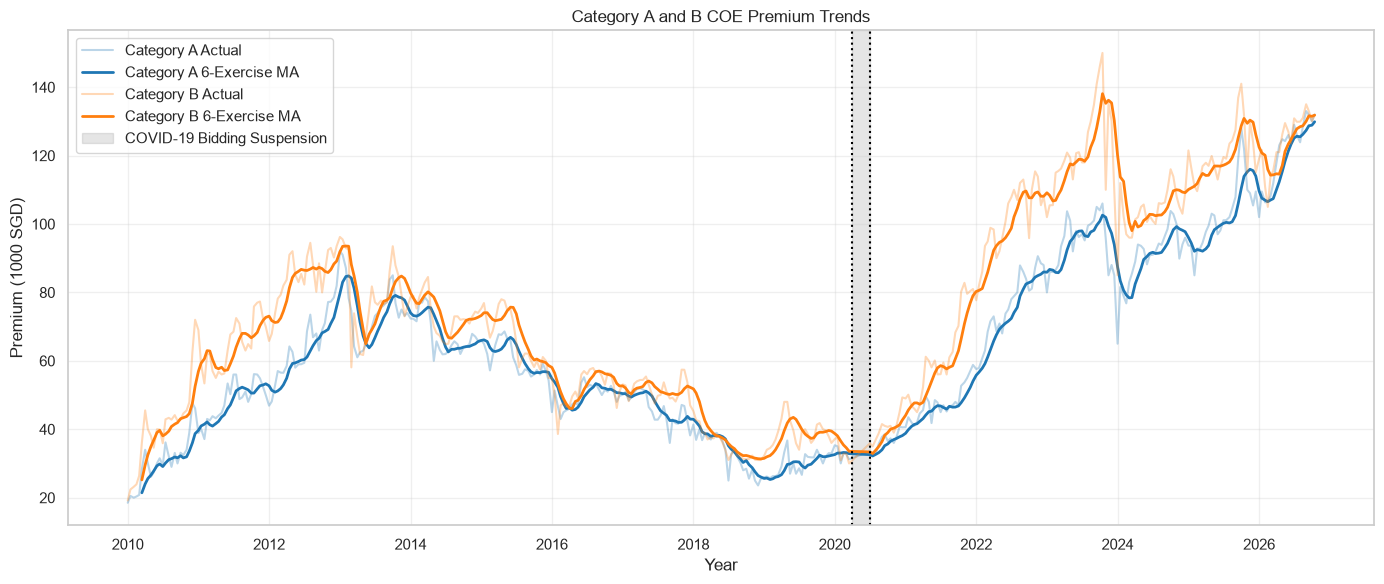

In [27]:
sns.set_theme(style="whitegrid")

# Create analysis dataset
coe_analysis = coe_wide.copy()

# Sort chronologically
coe_analysis = coe_analysis.sort_values(
    ["year", "month", "bidding_no"]
).reset_index(drop=True)

# Create exercise index
coe_analysis["exercise"] = np.arange(1, len(coe_analysis) + 1)

# Create approximate dates for plotting
coe_analysis["plot_date"] = (
    pd.to_datetime(coe_analysis["date"])
    + pd.to_timedelta(
        (coe_analysis["bidding_no"] - 1) * 14,
        unit="D"
    )
)

# Calculate 6-exercise moving averages
for category in ["A", "B"]:
    coe_analysis[f"premium_{category}_ma6"] = (
        coe_analysis[f"premium_{category}"]
        .rolling(window=6, min_periods=6)
        .mean()
    )

def plot_premium_trends(df, ax=None, annotations=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(14, 6))

    colors = {"A": "tab:blue", "B": "tab:orange"}

    for category in ["A", "B"]:
        ax.plot(
            df["plot_date"],
            df[f"premium_{category}"],
            color=colors[category],
            alpha=0.3,
            label=f"Category {category} Actual"
        )

        ax.plot(
            df["plot_date"],
            df[f"premium_{category}_ma6"],
            color=colors[category],
            linewidth=2,
            label=f"Category {category} 6-Exercise MA"
        )

    if annotations:
        add_annotations(ax)

    ax.set(
        title="Category A and B COE Premium Trends",
        xlabel="Year",
        ylabel="Premium (1000 SGD)"
    )

    ax.legend()
    return ax

plot_premium_trends(coe_analysis)
plt.tight_layout()
plt.show()


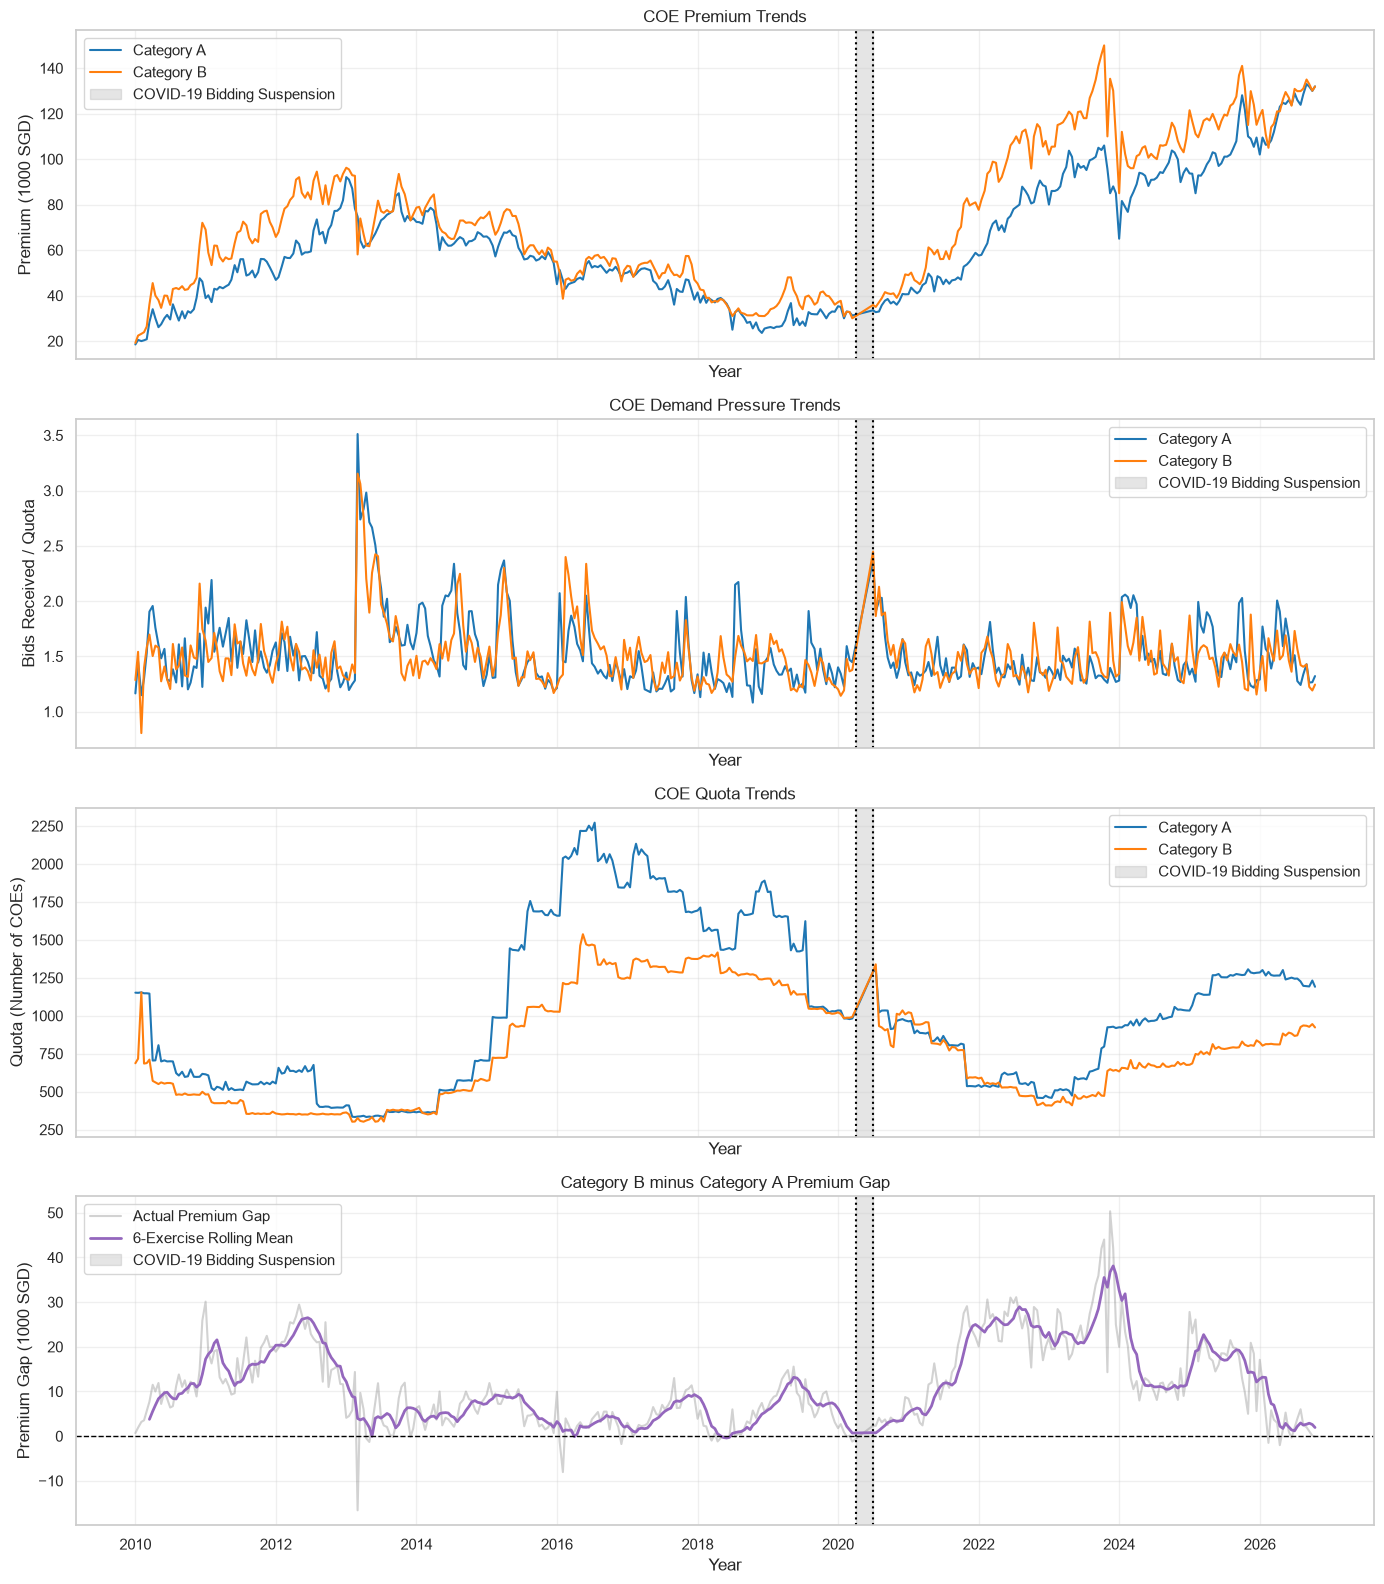

In [28]:

def plot_pressure_premium(df, annotations=True):

    df = df.copy()

    # Create plotting dates if they do not exist
    if "plot_date" not in df.columns:
        df["plot_date"] = (
            pd.to_datetime(df["date"])
            + pd.to_timedelta(
                (df["bidding_no"] - 1) * 14,
                unit="D"
            )
        )

    df = df.sort_values("plot_date").reset_index(drop=True)

    # Calculate premium gap and 6-exercise rolling mean
    df["gap"] = df["premium_B"] - df["premium_A"]

    df["gap_ma6"] = (
        df["gap"]
        .rolling(window=6, min_periods=6)
        .mean()
    )

    # Create four vertically stacked plots
    fig, axes = plt.subplots(
        4, 1,
        figsize=(14, 16),
        sharex=True
    )

    colors = {
        "A": "tab:blue",
        "B": "tab:orange"
    }

    variables = [
        ("premium", "COE Premium Trends", "Premium (1000 SGD)"),
        ("pressure", "COE Demand Pressure Trends", "Bids Received / Quota"),
        ("quota", "COE Quota Trends", "Quota (Number of COEs)")
    ]

    # Plots 1–3: Premium, pressure and quota
    for i, (variable, title, ylabel) in enumerate(variables):

        for category in ["A", "B"]:
            axes[i].plot(
                df["plot_date"],
                df[f"{variable}_{category}"],
                color=colors[category],
                linewidth=1.5,
                label=f"Category {category}"
            )

        axes[i].set(
            title=title,
            ylabel=ylabel
        )

        if annotations:
            add_annotations(axes[i])

        axes[i].legend()

    # Plot 4: Premium gap and rolling mean
    ax_gap = axes[3]

    ax_gap.plot(
        df["plot_date"],
        df["gap"],
        color="tab:gray",
        alpha=0.35,
        label="Actual Premium Gap"
    )

    ax_gap.plot(
        df["plot_date"],
        df["gap_ma6"],
        color="tab:purple",
        linewidth=2,
        label="6-Exercise Rolling Mean"
    )

    ax_gap.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax_gap.set(
        title="Category B minus Category A Premium Gap",
        ylabel="Premium Gap (1000 SGD)"
    )

    if annotations:
        add_annotations(ax_gap)

    ax_gap.legend()

    axes[-1].set_xlabel("Year")

    plt.tight_layout()

    return fig, axes


# Generate combined plots
fig, axes = plot_pressure_premium(coe_wide)
plt.show()

Key events marked by vertical red dashed lines\
2014: Change of Cat A classification to include 97kW power threshold\
2018: Zero vehicle population growth policy\
2022: Cat A power threshold for fully electric vehicles (EV) increased to 110 kW

Between 2010-2026, cat B premiums are consistently higher than cat A premiums (graph 1). This positive premium gap (graph 4) is in line with the policy objective of dedicating cat B COEs to higher value cars.

Pre-pandemic, wide premium gap is correlated with periods of increasing premiums. However after 2024, the premium gap began to close rapidly despite record high premiums. This is likely caused by higher demand pressure for cat A and lower demand for cat B (graph 2). Upward pressure on cat A premium is strong enough to close the premium gap despite the relatively higher quota/supply of cat A COEs (graph 3). We seek to investigate if EV buyers caused this disproportional increase in Cat A demand.

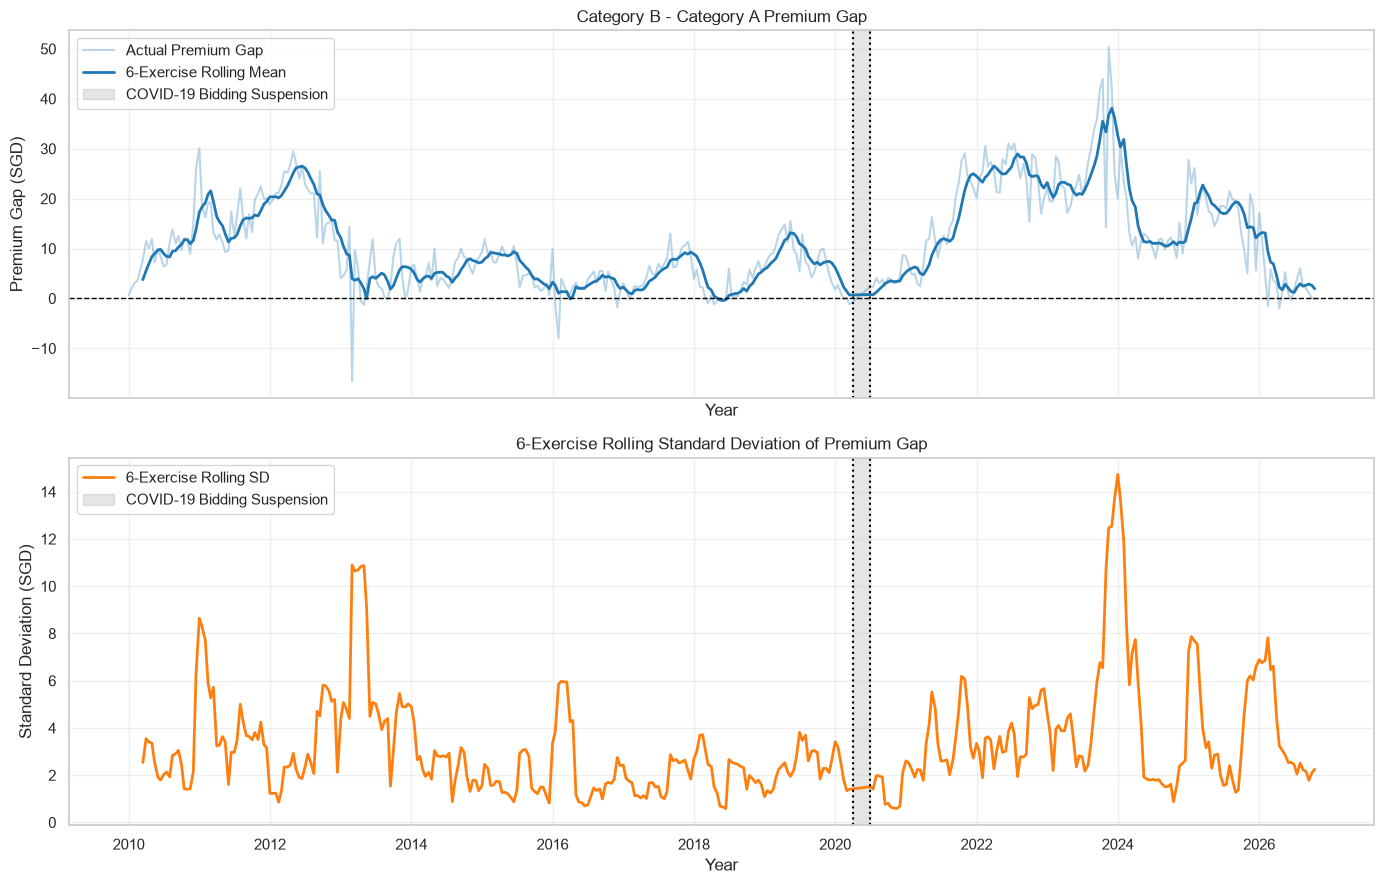

(<Figure size 1400x900 with 2 Axes>,
 array([<Axes: title={'center': 'Category B - Category A Premium Gap'}, xlabel='Year', ylabel='Premium Gap (SGD)'>,
        <Axes: title={'center': '6-Exercise Rolling Standard Deviation of Premium Gap'}, xlabel='Year', ylabel='Standard Deviation (SGD)'>],
       dtype=object))

In [29]:

def plot_volatility(coe_analysis, window=6):
    # Sort chronologically
    df = coe_analysis.sort_values(
        ["year", "month", "bidding_no"]
    ).reset_index(drop=True).copy()

    # Calculate premium gap
    df["gap"] = df["premium_B"] - df["premium_A"]

    # Calculate rolling statistics
    df["gap_ma"] = (
        df["gap"]
        .rolling(window=window, min_periods=window)
        .mean()
    )

    df["gap_sd"] = (
        df["gap"]
        .rolling(window=window, min_periods=window)
        .std()
    )

    # Create figure
    fig, axes = plt.subplots(
        2, 1,
        figsize=(14, 9),
        sharex=True
    )

    # Plot 1: Premium gap and rolling mean
    axes[0].plot(
        df["plot_date"],
        df["gap"],
        color="tab:blue",
        alpha=0.3,
        label="Actual Premium Gap"
    )

    axes[0].plot(
        df["plot_date"],
        df["gap_ma"],
        color="tab:blue",
        linewidth=2,
        label=f"{window}-Exercise Rolling Mean"
    )

    axes[0].axhline(
        0, color="black", linestyle="--", linewidth=1
    )

    axes[0].set(
        title="Category B - Category A Premium Gap",
        ylabel="Premium Gap (SGD)"
    )

    # Plot 2: Rolling standard deviation
    axes[1].plot(
        df["plot_date"],
        df["gap_sd"],
        color="tab:orange",
        linewidth=2,
        label=f"{window}-Exercise Rolling SD"
    )

    axes[1].set(
        title=f"{window}-Exercise Rolling Standard Deviation of Premium Gap",
        ylabel="Standard Deviation (SGD)"
    )

    # Event annotations
    for ax in axes:
        add_annotations(ax)
        ax.legend()

    plt.tight_layout()
    plt.show()

    return fig, axes

plot_volatility(coe_analysis, window=6)

To determine if the shrinking premium gap is sustained, we will compare the magnitute of the gap with its variability.

Using 2014-2020 as a benchmark, the consistently small premium gap coincides with low standard deviation (SD). In contrast, the short increase in premium gap between 2010-2013 is marked by higher SD. Therefore, verifing a long-term narrowing in premium gap should require a decrease in both magnitude and SD of the gap.

Between 2023-2026, high premium gaps is associated with large spikes in SD. This short-term widening may be caused by the Early Adoption Incentive (EEAI), where prospective EV buyers bring forward purchases to enjoy the rebate, which helps to offset part of the higher COE premiums. As this scheme is going to be phased out, more buyers may seek to purchase EVs in the Cat A band with cheaper premiums, driving up demand and increasing premiums. 

This could be a long term trend due to 2 reasons.
1. EV adoption is likely a long-term trend. More manufacturers will be incentivised to produce models tuned to meet the exact Cat A power threshold.
2. Statistically, the falling SD could indicate a stabalising low premium cap for the next few years.

### 4.2 Registrations Dataframe

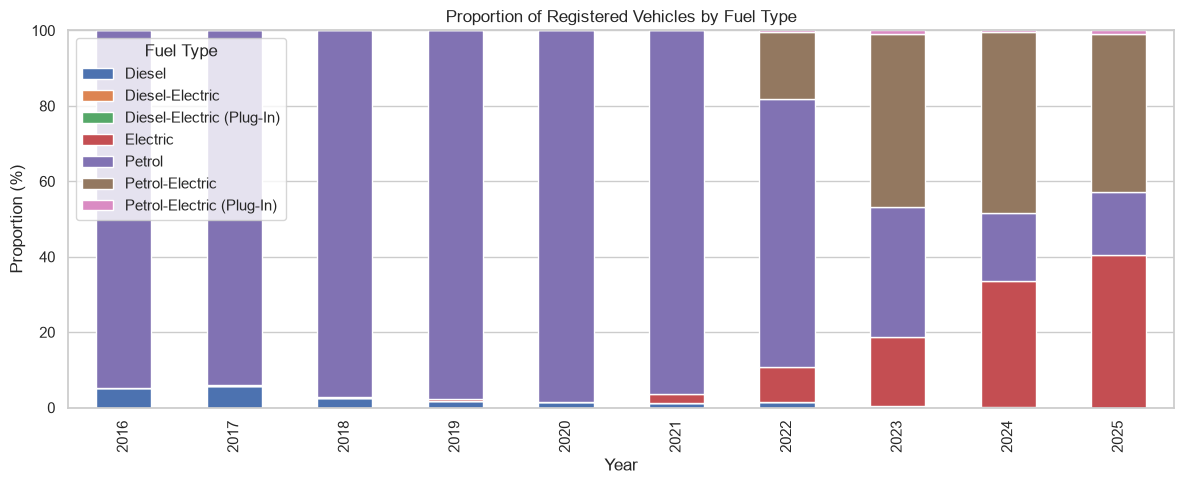

In [30]:
fuel_pct = (
    registrations_raw
    .groupby(["year", "fuel_type"])["number"]
    .sum()
    .unstack(fill_value=0)
)

fuel_pct = fuel_pct.div(fuel_pct.sum(axis=1), axis=0) * 100

fuel_pct.plot(kind="bar", stacked=True, figsize=(12, 5))

plt.title("Proportion of Registered Vehicles by Fuel Type")
plt.xlabel("Year")
plt.ylabel("Proportion (%)")
plt.legend(title="Fuel Type")
plt.tight_layout()
plt.show()

Increaseing proportion of petrol-electric (hybrid) and electric vehicles from 2022 onwards. By 2025, more than 80% of newly registered vehicles are fully or partly electric.

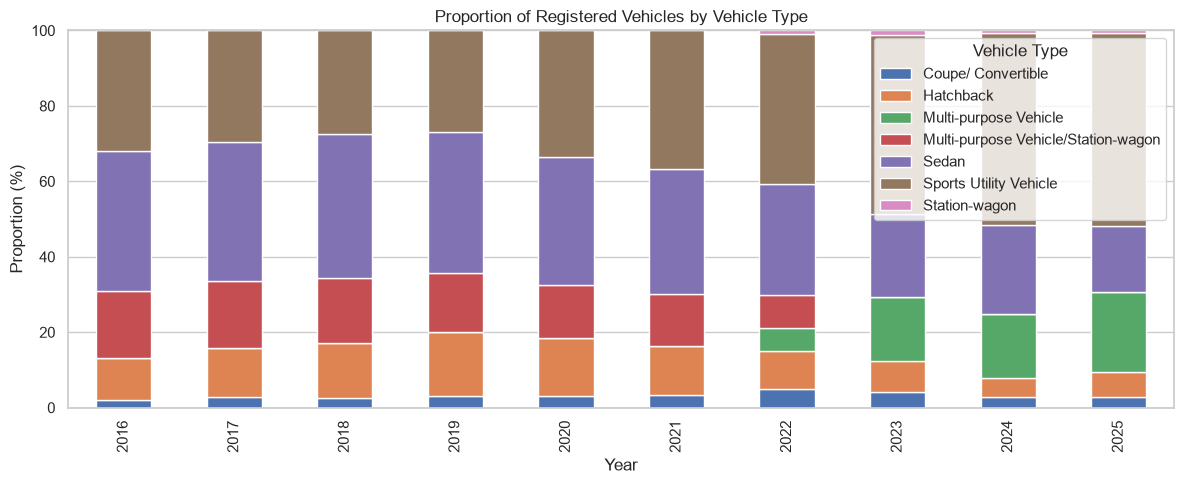

In [31]:
type_pct = (
    registrations_raw
    .groupby(["year", "vehicle_type"])["number"]
    .sum()
    .unstack(fill_value=0)
)

type_pct = type_pct.div(type_pct.sum(axis=1), axis=0) * 100

type_pct.plot(kind="bar", stacked=True, figsize=(12, 5))

plt.title("Proportion of Registered Vehicles by Vehicle Type")
plt.xlabel("Year")
plt.ylabel("Proportion (%)")
plt.legend(title="Vehicle Type")
plt.tight_layout()
plt.show()

Changing proportion of new vehicle type registered.
1. Higher proportion of SUVs (brown).
2. Decreasing proportion of hatchbacks (orange).

Whether this represents an increase in average vehicle value cannot be determined without model level price or OMV information.

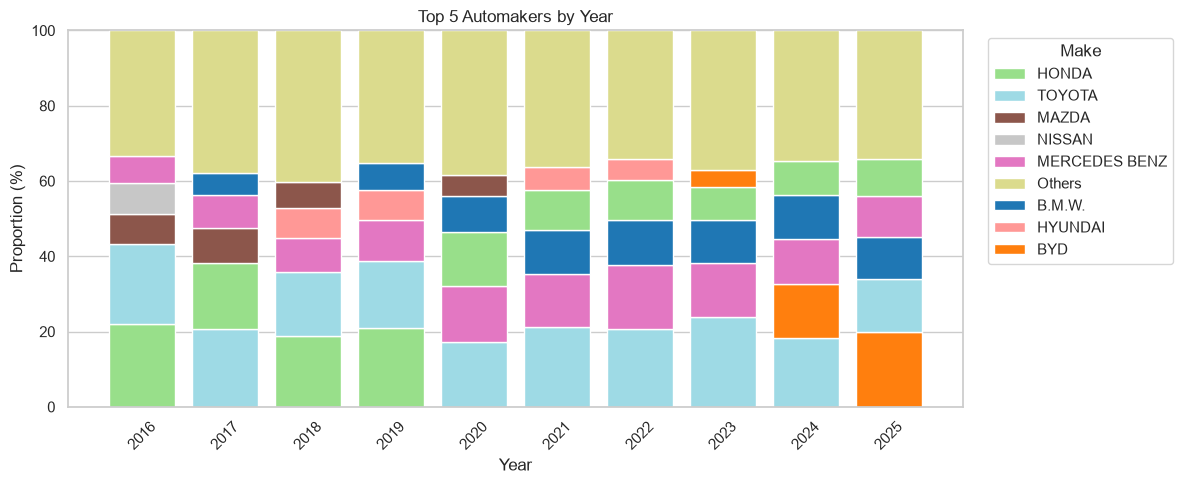

In [32]:
# Calculate registrations by year and make
make_df = (
    registrations_raw
    .groupby(["year", "make"], as_index=False)["number"]
    .sum()
)

# Rank automakers within each year
make_df["rank"] = (
    make_df.groupby("year")["number"]
    .rank(method="first", ascending=False)
)

# Group makes outside top 5 as Others
make_df["make"] = make_df["make"].where(
    make_df["rank"] <= 5, "Others"
)

# Calculate yearly proportions
make_pct = (
    make_df
    .groupby(["year", "make"])["number"]
    .sum()
    .unstack(fill_value=0)
)

make_pct = make_pct.div(make_pct.sum(axis=1), axis=0) * 100

# Assign consistent colors to makes
colors = dict(zip(
    make_pct.columns,
    plt.cm.tab20(np.linspace(0, 1, len(make_pct.columns)))
))

# Plot
fig, ax = plt.subplots(figsize=(12, 5))

for i, (year, row) in enumerate(make_pct.iterrows()):
    bottom = 0

    # Sort top 5 from largest to smallest
    sorted_makes = row.drop("Others").sort_values(ascending=False)

    # Keep Others at the top
    sorted_makes = pd.concat([sorted_makes, row[["Others"]]])

    for make, pct in sorted_makes.items():
        if pct > 0:
            ax.bar(
                i, pct,
                bottom=bottom,
                color=colors[make],
                label=make
            )
            bottom += pct

# Formatting
ax.set_xticks(range(len(make_pct.index)))
ax.set_xticklabels(make_pct.index, rotation=45)
ax.set_title("Top 5 Automakers by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Proportion (%)")
ax.set_ylim(0, 100)

# Remove duplicate legend entries
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))

ax.legend(
    unique.values(), unique.keys(),
    title="Make",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


In [33]:
top10_yearly = (
    registrations_raw
    .groupby(["year", "make"])["number"]
    .sum()
    .reset_index()
    .sort_values(["year", "number"], ascending=[True, False])
    .groupby("year")
    .head(10)
)
top10_table = (
    top10_yearly
    .assign(rank=lambda x: x.groupby("year").cumcount() + 1)
    .pivot(index="rank", columns="year", values="make")
)
display(
    top10_table.style.map(
        lambda x: "background-color: green" if x in ev_makes else ""
    )
)

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rank,,,,,,,,,,
1,HONDA,TOYOTA,HONDA,HONDA,TOYOTA,TOYOTA,TOYOTA,TOYOTA,TOYOTA,BYD
2,TOYOTA,HONDA,TOYOTA,TOYOTA,MERCEDES BENZ,MERCEDES BENZ,MERCEDES BENZ,MERCEDES BENZ,BYD,TOYOTA
3,MAZDA,MAZDA,MERCEDES BENZ,MERCEDES BENZ,HONDA,B.M.W.,B.M.W.,B.M.W.,MERCEDES BENZ,B.M.W.
4,NISSAN,MERCEDES BENZ,HYUNDAI,HYUNDAI,B.M.W.,HONDA,HONDA,HONDA,B.M.W.,MERCEDES BENZ
5,MERCEDES BENZ,B.M.W.,MAZDA,B.M.W.,MAZDA,HYUNDAI,HYUNDAI,BYD,HONDA,HONDA
6,B.M.W.,NISSAN,B.M.W.,KIA,AUDI,MAZDA,MAZDA,NISSAN,TESLA,TESLA
7,MITSUBISHI,KIA,NISSAN,MAZDA,HYUNDAI,AUDI,TESLA,MAZDA,HYUNDAI,HYUNDAI
8,SUBARU,HYUNDAI,KIA,MITSUBISHI,KIA,NISSAN,NISSAN,HYUNDAI,NISSAN,KIA
9,VOLKSWAGEN,MITSUBISHI,MITSUBISHI,AUDI,NISSAN,KIA,AUDI,KIA,MAZDA,MAZDA


Increasing market share of EV manufactureres, especially BYD and Tesla.

In 2025, Chinese manufacturer BYD alone makes up 20% of newly registered vehicles. Market share of traditional Japanese and European automakers are gradually decreasing.

## 5. Analysis & Modelling

*Instructions:* Explain your method and why you chose it. If you build a model:
- Use **time-based validation** (train on earlier data, test on later data). Do not use random splits.
- Compare against **simple baselines**, such as the previous round's premium or a rolling average.
- **Bids received** is only known after a round closes. Use it to explain premiums, not to forecast them.
- A merged Category A/B premium cannot be observed. If you model one, state your assumption and test how sensitive your results are to it.

A model is not required. A well-reasoned statistical or descriptive analysis is fine.

### 5.1 Linear Regression

#### 5.1.1 Linear Regression with COE Predictors

In [34]:
# Calculate monthly averages and sums for each vehicle class
# Monthly premium and pressure are exercise averages; quota is the monthly sum.
coe_monthly = (
    coe_ab.groupby(["date", "vehicle_class"], as_index=False)
    .agg(premium=("premium", "mean"), pressure=("pressure", "mean"), quota=("quota", "sum"))
)

def monthly_wide(variable):
    return (coe_monthly.pivot(index="date", columns="vehicle_class", values=variable)
            .sort_index().rename_axis(columns=None))

premium = monthly_wide("premium")
pressure = monthly_wide("pressure")
quota = monthly_wide("quota")
premium["difference"] = premium["Category B"] - premium["Category A"]

# Shift first, then calculate trailing averages: predictors exclude the target month.
premium_lag1 = premium[["Category A", "Category B"]].shift(1)
pressure_lag1 = pressure.shift(1)
premium_ma3 = premium_lag1.rolling(3, min_periods=3).mean()
pressure_ma3 = pressure_lag1.rolling(3, min_periods=3).mean()

In [35]:
# Linear regression
# Category A
model_data_a = pd.DataFrame({
    "premium": premium["Category A"],
    "premium_lag1": premium_lag1["Category A"],
    "pressure_lag1": pressure_lag1["Category A"]
}).dropna()

# Category B
model_data_b = pd.DataFrame({
    "premium": premium["Category B"],
    "premium_lag1": premium_lag1["Category B"],
    "pressure_lag1": pressure_lag1["Category B"]
}).dropna()

# Training: up to 2024
train_a = model_data_a.loc[: "2024-12-01"]
train_b = model_data_b.loc[: "2024-12-01"]

# Validation: 2025-2026
val_a = model_data_a.loc["2025-01-01":"2026-12-01"]
val_b = model_data_b.loc["2025-01-01":"2026-12-01"]

# Model 1: Category A
x_train_a = sm.add_constant(train_a[["premium_lag1", "pressure_lag1"]])
y_train_a = train_a["premium"]

model_a_baseline = sm.OLS(y_train_a, x_train_a).fit()

# Model 2: Category B
x_train_b = sm.add_constant(train_b[["premium_lag1", "pressure_lag1"]])
y_train_b = train_b["premium"]

model_b_baseline = sm.OLS(y_train_b, x_train_b).fit()

# Regression summaries
print("Category A")
print(model_a_baseline.summary())

print("\nCategory B")
print(model_b_baseline.summary())

# Category A predictions
x_val_a = sm.add_constant(
    val_a[["premium_lag1", "pressure_lag1"]],
    has_constant="add"
)

pred_a_baseline = model_a_baseline.predict(x_val_a)

# Category B predictions
x_val_b = sm.add_constant(
    val_b[["premium_lag1", "pressure_lag1"]],
    has_constant="add"
)

pred_b_baseline = model_b_baseline.predict(x_val_b)

# Evaluation function
def evaluate(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

baseline_results = pd.DataFrame({
    "Category A": evaluate(val_a["premium"], pred_a_baseline),
    "Category B": evaluate(val_b["premium"], pred_b_baseline)
}).T

display(baseline_results.round(3))

Category A
                            OLS Regression Results                            
Dep. Variable:                premium   R-squared:                       0.959
Model:                            OLS   Adj. R-squared:                  0.959
Method:                 Least Squares   F-statistic:                     2035.
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          6.36e-121
Time:                        11:51:02   Log-Likelihood:                -504.85
No. Observations:                 176   AIC:                             1016.
Df Residuals:                     173   BIC:                             1025.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.2873      1.830

,RMSE,MAE,R2
Category A,6.253,4.732,0.770
Category B,6.816,5.785,0.196


Coeffifients of `pressure_lag1` of both linear regression models have a p-value > 0.05, indicating that they are not significant at 95% confidence level. Based on the available range of predictors, each round's premium is highly correlated with that of the previous bidding round.

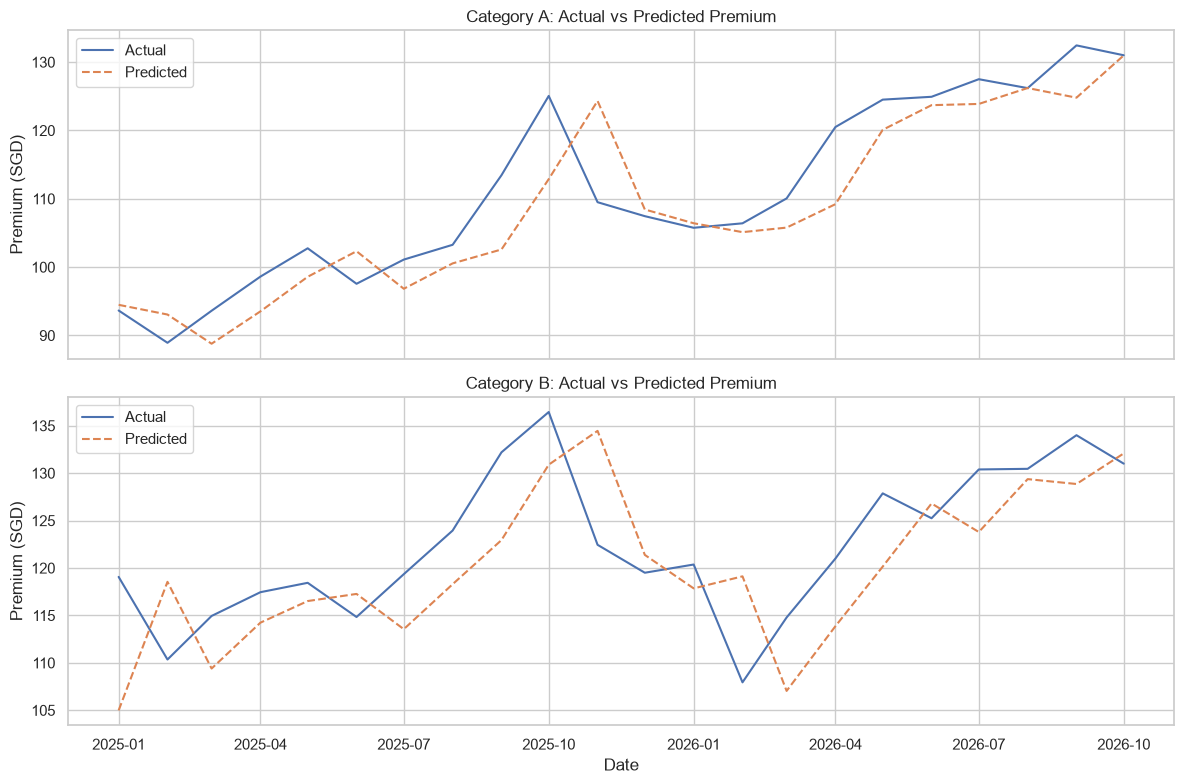

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Category A
axes[0].plot(val_a.index, val_a["premium"], label="Actual")
axes[0].plot(val_a.index, pred_a_baseline, label="Predicted", linestyle="--")
axes[0].set_title("Category A: Actual vs Predicted Premium")
axes[0].set_ylabel("Premium (SGD)")
axes[0].legend()

# Category B
axes[1].plot(val_b.index, val_b["premium"], label="Actual")
axes[1].plot(val_b.index, pred_b_baseline, label="Predicted", linestyle="--")
axes[1].set_title("Category B: Actual vs Predicted Premium")
axes[1].set_ylabel("Premium (SGD)")
axes[1].set_xlabel("Date")
axes[1].legend()

plt.tight_layout()
plt.show()

In [37]:
# Correlaton matrix for premium and demand pressure (current month)
# Combine monthly premiums and demand pressure
corr_data_57 = pd.DataFrame({
    "Premium A": premium["Category A"],
    "Premium B": premium["Category B"],
    "Pressure A": pressure["Category A"],
    "Pressure B": pressure["Category B"],
})

# Calculate correlation matrix
corr_matrix = corr_data_57.corr()

display(corr_matrix.round(3))

,Premium A,Premium B,Pressure A,Pressure B
Premium A,1.000,0.960,0.064,0.024
Premium B,0.960,1.000,0.011,-0.015
Pressure A,0.064,0.011,1.000,0.750
Pressure B,0.024,-0.015,0.750,1.000


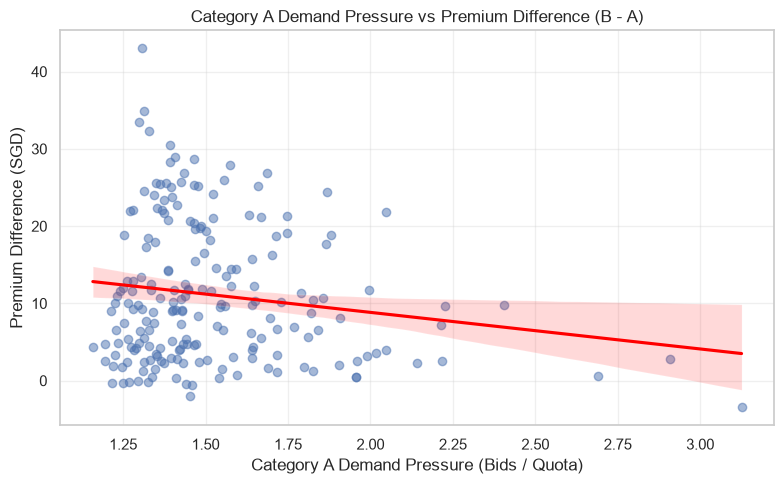

Correlation: -0.153


In [38]:
# Prepare data
pressure_gap_plot_data = pd.DataFrame({
    "Premium Difference": premium["Category B"] - premium["Category A"],
    "Pressure A": pressure["Category A"]
}).dropna()

# Scatter plot with regression line
plt.figure(figsize=(8, 5))

sns.regplot(
    data=pressure_gap_plot_data,
    x="Pressure A",
    y="Premium Difference",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Category A Demand Pressure vs Premium Difference (B - A)")
plt.xlabel("Category A Demand Pressure (Bids / Quota)")
plt.ylabel("Premium Difference (SGD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Pearson correlation
print("Correlation:", round(
    pressure_gap_plot_data["Pressure A"].corr(pressure_gap_plot_data["Premium Difference"]), 3
))

There is a slight negative correlation between Cat A demand pressure and premium gap. This is in line with our hypothesis that buyers of high OMV cars tuned to Cat A specifications are increasing Cat A COE demand while reducing that of Cat B.

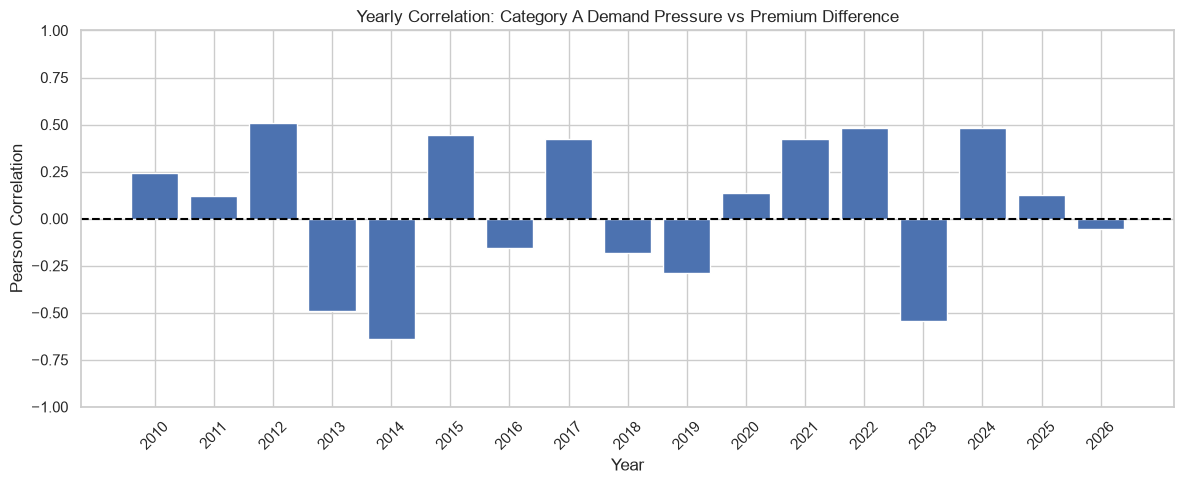

In [39]:
# Prepare data
corr_data_59 = pd.DataFrame({
    "Pressure A": pressure["Category A"],
    "Premium Difference": premium["Category B"] - premium["Category A"]
}).dropna()

# Calculate yearly correlations
yearly_corr = (
    corr_data_59
    .groupby(corr_data_59.index.year)
    .apply(lambda x: x["Pressure A"].corr(x["Premium Difference"]))
)

# Plot
plt.figure(figsize=(12, 5))
plt.bar(yearly_corr.index, yearly_corr.values)

plt.title("Yearly Correlation: Category A Demand Pressure vs Premium Difference")
plt.xlabel("Year")
plt.ylabel("Pearson Correlation")
plt.ylim(-1, 1)
plt.axhline(0, color="black", linestyle="--")
plt.xticks(yearly_corr.index, rotation=45)
plt.tight_layout()
plt.show()

However, the correlation between Cat A demand pressure and A-B premium difference experiences significant variation. There may be other underlying factors not represented in our dataset.

#### 5.1.2 Regression with EV Data Combined

In [40]:
# Monthly vehicle registrations by fuel type
ev_df = registrations_raw.copy()

ev_df["date"] = pd.to_datetime(
    ev_df[["year", "month"]].assign(day=1)
)

# Calculate monthly EV share
ev_df["electric_number"] = np.where(
    ev_df["fuel_type"].str.strip().str.lower() == "electric",
    ev_df["number"],
    0
)

ev_share = (
    ev_df
    .groupby("date")
    .agg(
        electric=("electric_number", "sum"),
        total=("number", "sum")
    )
)

ev_share["ev_share"] = (
    ev_share["electric"] / ev_share["total"].replace(0, np.nan)
)

ev_share = ev_share["ev_share"]


In [41]:
# monthly quota by vehicle class
quota = (
    coe_ab
    .groupby(["date", "vehicle_class"])["quota"]
    .sum()
    .unstack()
    .reindex(premium.index)
)

In [42]:
# Prepare registration data
ev_df = registrations_raw.copy()

ev_df["date"] = pd.to_datetime(
    ev_df[["year", "month"]].assign(day=1)
)

# Identify electric vehicles
ev_df["electric_number"] = np.where(
    ev_df["fuel_type"].str.strip().str.lower() == "electric",
    ev_df["number"],
    0
)

# Monthly EV proportion
ev_share = (
    ev_df
    .groupby("date")
    .agg(
        electric=("electric_number", "sum"),
        total=("number", "sum")
    )
)

ev_share["ev_share"] = (
    ev_share["electric"] /
    ev_share["total"].replace(0, np.nan)
)

# Previous month's EV proportion
ev_share_lag1 = ev_share["ev_share"].reindex(premium.index).shift(1)

# Monthly quota by COE category
quota = (
    coe_ab
    .groupby(["date", "vehicle_class"])["quota"]
    .sum(min_count=1)
    .unstack()
    .reindex(premium.index)
)

# Previous month's quota
quota_lag1 = quota.shift(1)

# Category A
model_data_a = pd.DataFrame({
    "premium": premium["Category A"],
    "ev_share_lag1": ev_share_lag1,
    "pressure_ma3": pressure_ma3["Category A"],
    "premium_ma3": premium_ma3["Category A"],
    "quota_lag1": quota_lag1["Category A"]
})

# Category B
model_data_b = pd.DataFrame({
    "premium": premium["Category B"],
    "ev_share_lag1": ev_share_lag1,
    "pressure_ma3": pressure_ma3["Category B"],
    "premium_ma3": premium_ma3["Category B"],
    "quota_lag1": quota_lag1["Category B"]
})

# Restrict to overlapping period
model_data_a = model_data_a.loc["2016-01-01":"2025-05-01"].dropna()
model_data_b = model_data_b.loc["2016-01-01":"2025-05-01"].dropna()

# Training: 2016-2024
train_a = model_data_a.loc[:"2024-12-01"]
train_b = model_data_b.loc[:"2024-12-01"]

# Validation: Jan-May 2025
val_a = model_data_a.loc["2025-01-01":]
val_b = model_data_b.loc["2025-01-01":]
predictors = [
    "ev_share_lag1",
    "pressure_ma3",
    "premium_ma3",
    "quota_lag1"
]

# Category A
x_train_a = sm.add_constant(train_a[predictors])
y_train_a = train_a["premium"]

lm3 = sm.OLS(y_train_a, x_train_a).fit()

# Category B
x_train_b = sm.add_constant(train_b[predictors])
y_train_b = train_b["premium"]

lm4 = sm.OLS(y_train_b, x_train_b).fit()

print("Category A")
print(lm3.summary())

print("\nCategory B")
print(lm4.summary())

Category A
                            OLS Regression Results                            
Dep. Variable:                premium   R-squared:                       0.965
Model:                            OLS   Adj. R-squared:                  0.964
Method:                 Least Squares   F-statistic:                     685.0
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           3.47e-71
Time:                        11:51:02   Log-Likelihood:                -304.63
No. Observations:                 104   AIC:                             619.3
Df Residuals:                      99   BIC:                             632.5
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -7.5572      5.839

In [43]:
predictors = [
    "ev_share_lag1",
    "pressure_ma3",
    "premium_ma3",
    "quota_lag1"
]

# Category A
x_val_a = sm.add_constant(
    val_a[predictors],
    has_constant="add"
)

pred_a_extended = lm3.predict(x_val_a)

# Category B
x_val_b = sm.add_constant(
    val_b[predictors],
    has_constant="add"
)

pred_b_extended = lm4.predict(x_val_b)

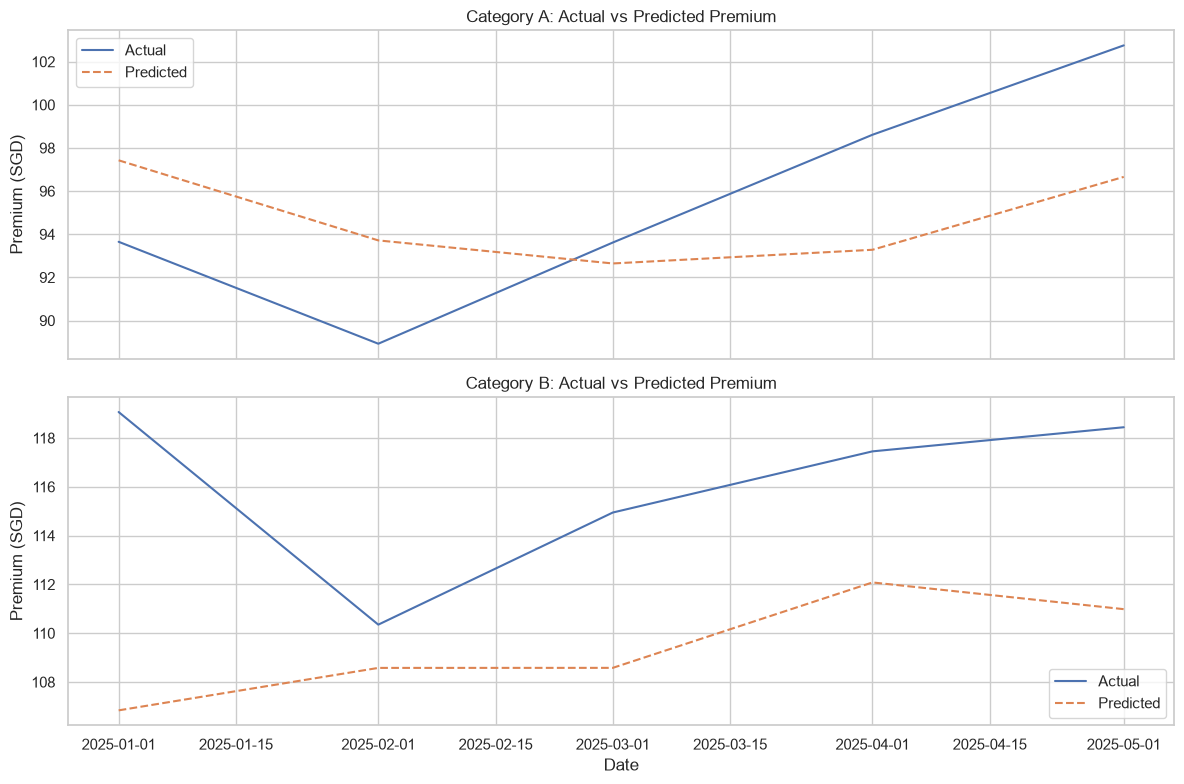

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Category A
axes[0].plot(val_a.index, val_a["premium"], label="Actual")
axes[0].plot(val_a.index, pred_a_extended, label="Predicted", linestyle="--")
axes[0].set_title("Category A: Actual vs Predicted Premium")
axes[0].set_ylabel("Premium (SGD)")
axes[0].legend()

# Category B
axes[1].plot(val_b.index, val_b["premium"], label="Actual")
axes[1].plot(val_b.index, pred_b_extended, label="Predicted", linestyle="--")
axes[1].set_title("Category B: Actual vs Predicted Premium")
axes[1].set_ylabel("Premium (SGD)")
axes[1].set_xlabel("Date")
axes[1].legend()

plt.tight_layout()
plt.show()

### 5.2 Evaluating New Policy

#### 5.2.1 Determine New Pricing Metric

In [45]:
# Historical hypothetical merger dataset
merger_df = coe_wide[
    ["year", "month", "bidding_no", "date",
     "premium_A", "premium_B", "quota_A", "quota_B"]
].copy()

merger_df = merger_df.sort_values(
    ["year", "month", "bidding_no"]
).reset_index(drop=True)

merger_df["plot_date"] = (
    merger_df["date"]
    + pd.to_timedelta(
        (merger_df["bidding_no"] - 1) * 14,
        unit="D"
    )
)

# Exclude observations with invalid or missing quotas/premiums
merger_df = merger_df.dropna(
    subset=["premium_A", "premium_B", "quota_A", "quota_B"]
).copy()

merger_df = merger_df[
    (merger_df["quota_A"] > 0) &
    (merger_df["quota_B"] > 0)
].copy()

merger_df["total_quota"] = (
    merger_df["quota_A"] + merger_df["quota_B"]
)

merger_df["quota_share_A"] = (
    merger_df["quota_A"] / merger_df["total_quota"]
)

# Hypothetical premiums
merger_df["merged_simple"] = (
    merger_df["premium_A"] + merger_df["premium_B"]
) / 2

merger_df["merged_weighted"] = (
    merger_df["quota_A"] * merger_df["premium_A"]
    + merger_df["quota_B"] * merger_df["premium_B"]
) / merger_df["total_quota"]

display(merger_df.head())

,year,month,bidding_no,date,premium_A,premium_B,quota_A,quota_B,plot_date,total_quota,quota_share_A,merged_simple,merged_weighted
0,2010,1,1,2010-01-01,18.502,19.190,1152.0,687.0,2010-01-01,1839.0,0.626427,18.8460,18.759018
1,2010,1,2,2010-01-01,20.501,22.400,1151.0,717.0,2010-01-15,1868.0,0.616167,21.4505,21.229899
2,2010,2,1,2010-02-01,19.989,23.180,1154.0,1154.0,2010-02-01,2308.0,0.500000,21.5845,21.584500
3,2010,2,2,2010-02-01,20.340,23.889,1148.0,685.0,2010-02-15,1833.0,0.626296,22.1145,21.666277
4,2010,3,1,2010-03-01,20.802,26.389,1148.0,688.0,2010-03-01,1836.0,0.625272,23.5955,22.895603


Under the proposed new policy, Cat A and B will be combined into a single category. We backtested the merged price using 2 methods.\
P --> Price (premium)\
Q --> Quantity (quota)

1. Simple average\
P_merged = (P_A + P_B) / 2
2. Weighted average\
P_merged = (P_A * Q_A + P_B * Q_B) / (Q_A + Q_B)

In [46]:

for method in ["simple", "weighted"]:
    merged = merger_df[f"merged_{method}"]

    for category in ["A", "B"]:
        actual = merger_df[f"premium_{category}"]

        merger_df[f"impact_{category}_{method}"] = (
            merged - actual
        )

        merger_df[f"impact_{category}_{method}_pct"] = (
            (merged - actual) / actual * 100
        )

impact_summary = pd.DataFrame({
    "Metric": [
        "Mean impact on A",
        "Median impact on A",
        "Mean impact on B",
        "Median impact on B",
        "Mean % impact on A",
        "Mean % impact on B"
    ],
    "Simple average": [
        merger_df["impact_A_simple"].mean(),
        merger_df["impact_A_simple"].median(),
        merger_df["impact_B_simple"].mean(),
        merger_df["impact_B_simple"].median(),
        merger_df["impact_A_simple_pct"].mean(),
        merger_df["impact_B_simple_pct"].mean()
    ],
    "Quota-weighted": [
        merger_df["impact_A_weighted"].mean(),
        merger_df["impact_A_weighted"].median(),
        merger_df["impact_B_weighted"].mean(),
        merger_df["impact_B_weighted"].median(),
        merger_df["impact_A_weighted_pct"].mean(),
        merger_df["impact_B_weighted_pct"].mean()
    ]
})

display(impact_summary.round(2))

,Metric,Simple average,Quota-weighted
0,Mean impact on A,5.56,4.83
1,Median impact on A,4.50,3.96
2,Mean impact on B,-5.56,-6.28
3,Median impact on B,-4.50,-5.12
4,Mean % impact on A,9.38,8.20
5,Mean % impact on B,-7.28,-8.20


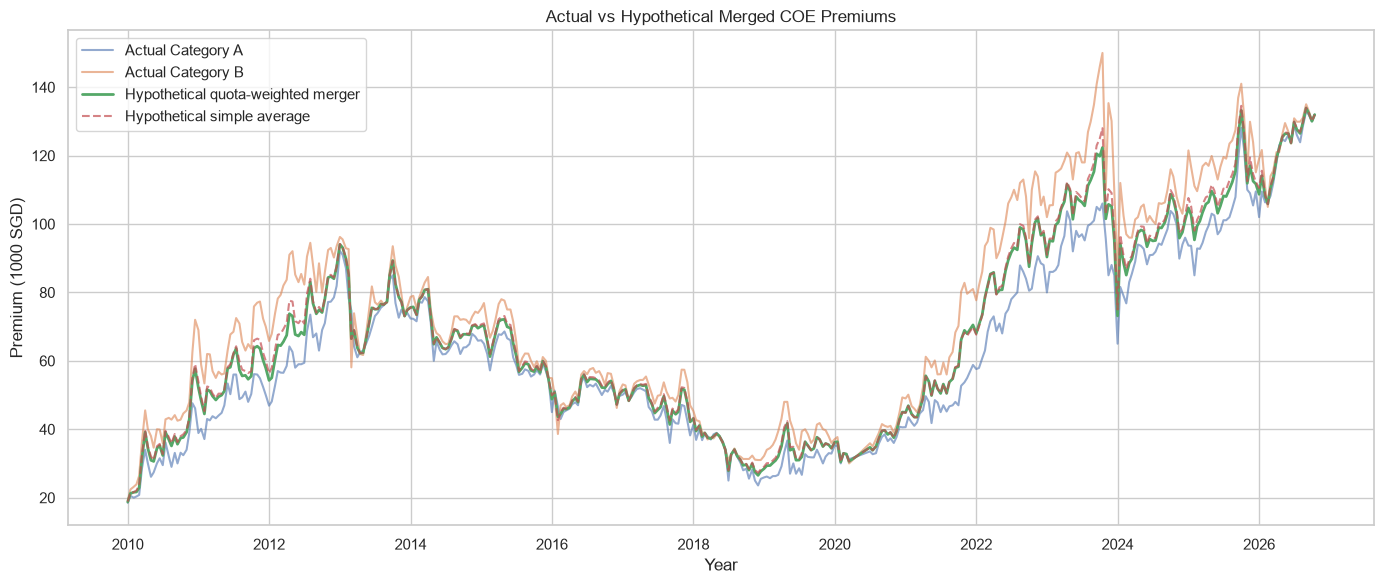

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Actual vs Hypothetical Merged COE Premiums'}, xlabel='Year', ylabel='Premium (1000 SGD)'>)

In [47]:
def plot_merged_premiums(df):
    fig, ax = plt.subplots(figsize=(14, 6))

    ax.plot(
        df["plot_date"], df["premium_A"],
        label="Actual Category A", alpha=0.6
    )
    ax.plot(
        df["plot_date"], df["premium_B"],
        label="Actual Category B", alpha=0.6
    )
    ax.plot(
        df["plot_date"], df["merged_weighted"],
        label="Hypothetical quota-weighted merger",
        linewidth=2
    )
    ax.plot(
        df["plot_date"], df["merged_simple"],
        label="Hypothetical simple average",
        linestyle="--", alpha=0.7
    )

    ax.set(
        title="Actual vs Hypothetical Merged COE Premiums",
        xlabel="Year",
        ylabel="Premium (1000 SGD)"
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

    return fig, ax

plot_merged_premiums(merger_df)

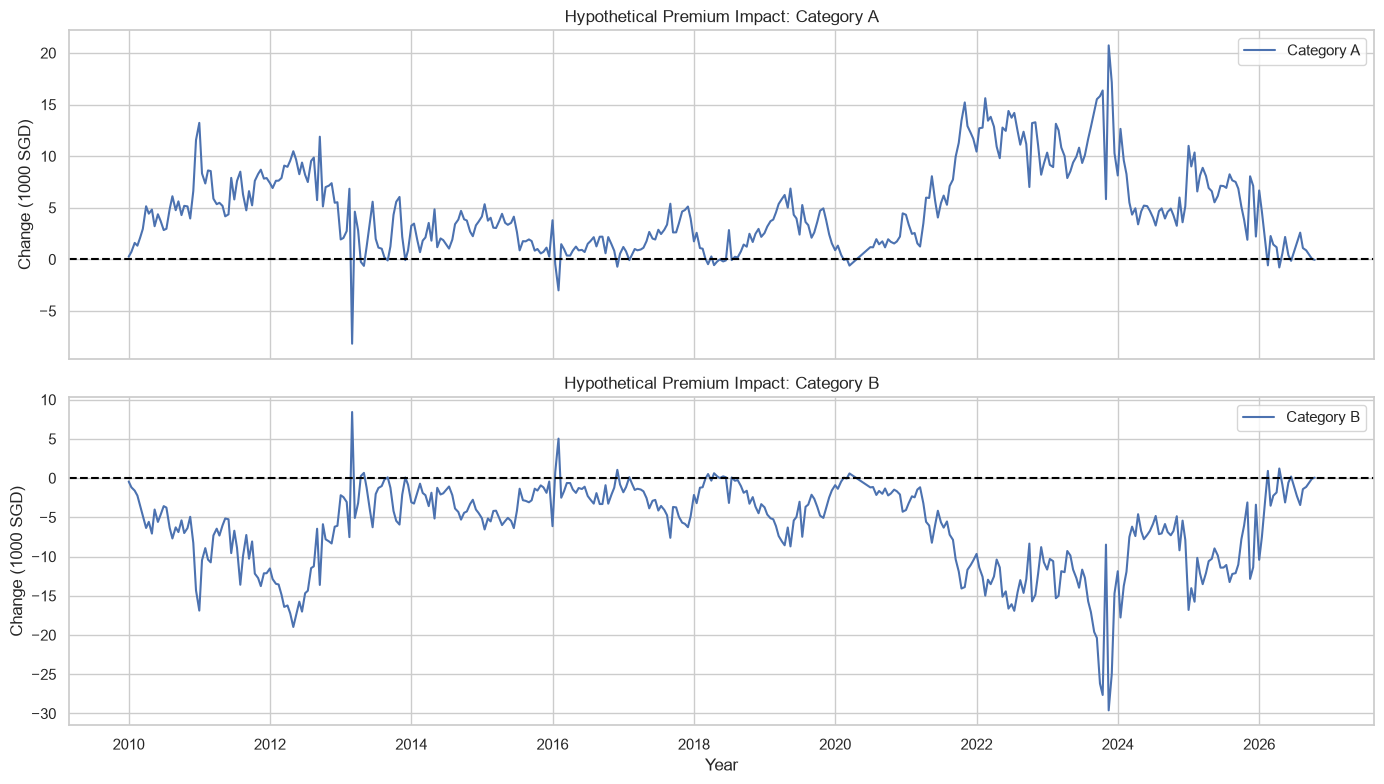

(<Figure size 1400x800 with 2 Axes>,
 array([<Axes: title={'center': 'Hypothetical Premium Impact: Category A'}, ylabel='Change (1000 SGD)'>,
        <Axes: title={'center': 'Hypothetical Premium Impact: Category B'}, xlabel='Year', ylabel='Change (1000 SGD)'>],
       dtype=object))

In [48]:
def plot_merger_impact(df):
    fig, axes = plt.subplots(
        2, 1, figsize=(14, 8), sharex=True
    )

    for ax, category in zip(axes, ["A", "B"]):
        ax.plot(
            df["plot_date"],
            df[f"impact_{category}_weighted"],
            label=f"Category {category}"
        )

        ax.axhline(0, color="black", linestyle="--")
        ax.set(
            title=f"Hypothetical Premium Impact: Category {category}",
            ylabel="Change (1000 SGD)"
        )
        ax.legend()

    axes[-1].set_xlabel("Year")
    plt.tight_layout()
    plt.show()

    return fig, axes

plot_merger_impact(merger_df)

In [49]:
# Compare volatility of actual vs hypothetical premiums
premium_cols = [
    "premium_A",
    "premium_B",
    "merged_simple",
    "merged_weighted"
]

volatility_results = []

for col in premium_cols:
    changes = merger_df[col].diff()

    volatility_results.append({
        "Series": col,
        "Premium SD": merger_df[col].std(),
        "Change SD": changes.std(),
        "Mean absolute change": changes.abs().mean(),
        "Largest increase": changes.max(),
        "Largest decrease": changes.min()
    })

volatility_summary = pd.DataFrame(volatility_results)

display(volatility_summary.round(2))

,Series,Premium SD,Change SD,Mean absolute change,Largest increase,Largest decrease
0,premium_A,26.73,3.87,2.81,16.58,-19.99
1,premium_B,30.64,5.68,3.65,26.99,-40.00
2,merged_simple,28.37,4.16,2.89,21.78,-25.16
3,merged_weighted,28.02,4.04,2.83,21.09,-22.15


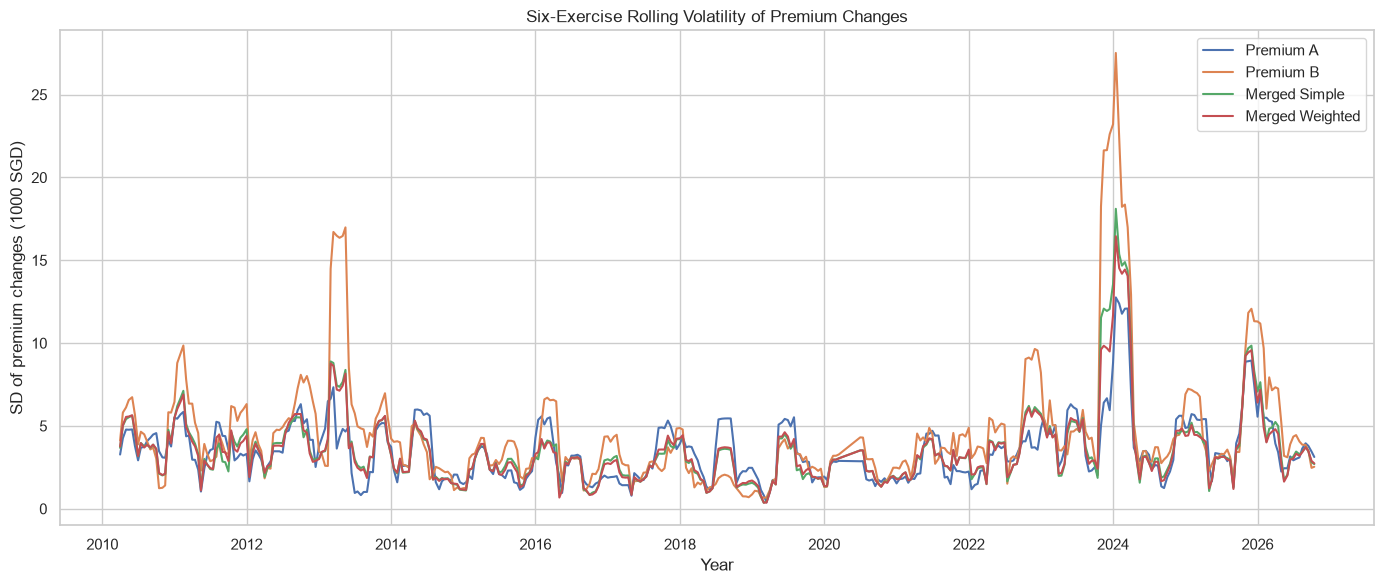

In [50]:
# Rolling volatility chart
for col in premium_cols:
    merger_df[f"{col}_sd6"] = (
        merger_df[col]
        .diff()
        .rolling(window=6, min_periods=6)
        .std()
    )

fig, ax = plt.subplots(figsize=(14, 6))

for col in premium_cols:
    ax.plot(
        merger_df["plot_date"],
        merger_df[f"{col}_sd6"],
        label=col.replace("_", " ").title()
    )

ax.set(
    title="Six-Exercise Rolling Volatility of Premium Changes",
    xlabel="Year",
    ylabel="SD of premium changes (1000 SGD)"
)

ax.legend()
plt.tight_layout()
plt.show()


#### 5.2.2 Effectiveness of rebates

The primary aim of the new COE policy should be to segment car buyers based on the car-value. This is a proxy of income and hence purchasing power. It is important to distinguish this from the utilty derived from car ownership, which may not be correlated with income. 

Therefore, the feebate must sufficiently offset the increase in COE prices from the original Cat A premium to preserve the purchasing power of Cat A car buyers. This avoids unnecessary deadweight loss.

In [51]:
# Testing effectiveness of $15,000 rebate on Cat A COE premiums
MAX_REBATE = 15.0  # 1000 SGD

merger_df["required_rebate_A"] = (
    merger_df["impact_A_weighted"]
    .clip(lower=0)
)

merger_df["rebate_sufficient"] = (
    merger_df["required_rebate_A"] <= MAX_REBATE
)

merger_df["effective_A_with_rebate"] = (
    merger_df["merged_weighted"] - MAX_REBATE
)

merger_df["net_impact_A"] = (
    merger_df["effective_A_with_rebate"]
    - merger_df["premium_A"]
)

rebate_summary = pd.Series({
    "Mean required rebate (1000 SGD)":
        merger_df["required_rebate_A"].mean(),

    "Median required rebate (1000 SGD)":
        merger_df["required_rebate_A"].median(),

    "Maximum required rebate (1000 SGD)":
        merger_df["required_rebate_A"].max(),

    "Exercises where 15k rebate is sufficient (%)":
        merger_df["rebate_sufficient"].mean() * 100,

    "Exercises where 15k rebate is insufficient (%)":
        (~merger_df["rebate_sufficient"]).mean() * 100
})

display(rebate_summary.round(2))


Mean required rebate (1000 SGD)                    4.87
Median required rebate (1000 SGD)                  3.96
Maximum required rebate (1000 SGD)                20.74
Exercises where 15k rebate is sufficient (%)      98.24
Exercises where 15k rebate is insufficient (%)     1.76
dtype: float64

Backtesting shows that the proposed maximum feebate of $15,000 is effective in terms of offseting higher premiums for original Cat A buyers. The "new" COE premium increase is below $15,000 a majority (98.24%) of the time.

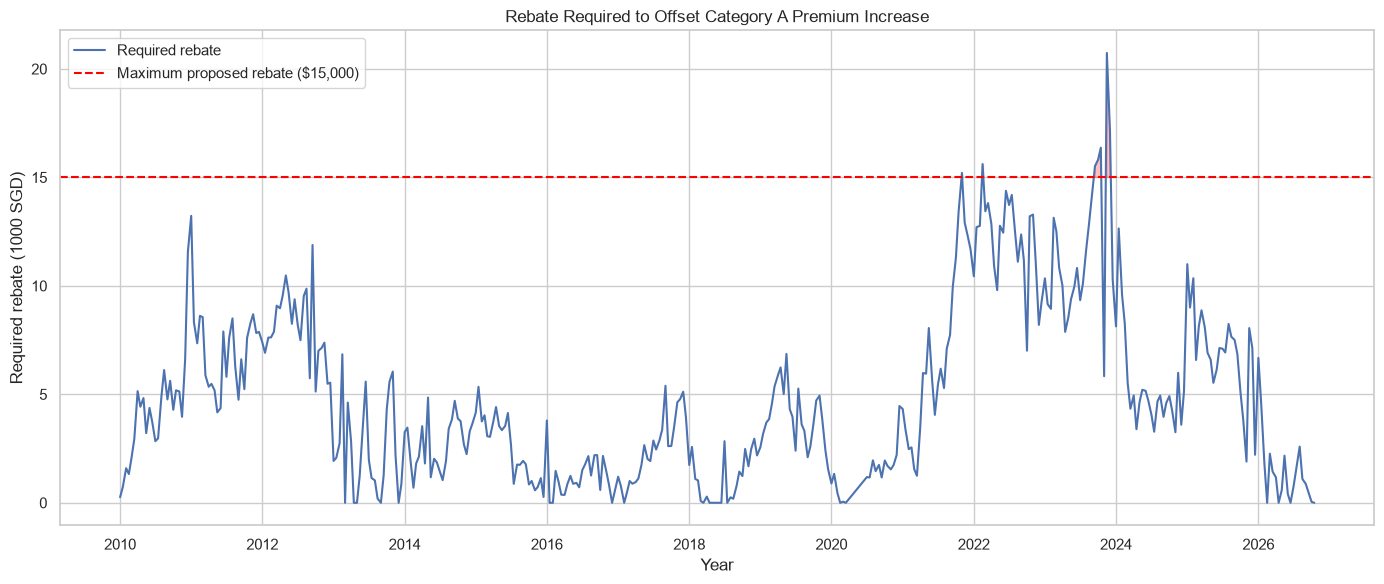

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Rebate Required to Offset Category A Premium Increase'}, xlabel='Year', ylabel='Required rebate (1000 SGD)'>)

In [52]:
def plot_max_rebate(df, max_rebate=15.0):
    fig, ax = plt.subplots(figsize=(14, 6))

    ax.plot(
        df["plot_date"],
        df["required_rebate_A"],
        label="Required rebate"
    )

    ax.axhline(
        max_rebate,
        color="red",
        linestyle="--",
        label=f"Maximum proposed rebate (${max_rebate * 1000:,.0f})"
    )

    ax.fill_between(
        df["plot_date"],
        df["required_rebate_A"],
        max_rebate,
        where=df["required_rebate_A"] > max_rebate,
        alpha=0.25,
        color="red"
    )

    ax.set(
        title="Rebate Required to Offset Category A Premium Increase",
        xlabel="Year",
        ylabel="Required rebate (1000 SGD)"
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

    return fig, ax

plot_max_rebate(merger_df, max_rebate=15.0)

However, having a fixed rebate has its downsides. From the chart above, the required feebate is highly correlated with the Cat A-B premium gap. During periods with low gaps (e.g. 2013-2021), the $15,000 feebate is significantly higher than the required value. 

This has 2 main impacts.
1. Lost government income due to a decrease in net COE revenue.
2. Reduces the effectiveness of the COE's primary objective (discourage car ownership). The feebate distorts the premium's price signials. Artificially low COE prices for mass-market cars can incentivise car ownership.

These impacts are particularly important considering the prevoiusly mentioned sustained narrowing in Cat A-B price gap.

In [53]:
# Calculate premium gap
merger_df["premium_gap"] = (
    merger_df["premium_B"] - merger_df["premium_A"]
)

# Summary statistics
gap_stats = merger_df["premium_gap"].agg(
    ["mean", "median", "std", "min", "max"]
)

print(gap_stats.round(2))

mean      11.11
median     9.01
std        9.32
min      -16.60
max       50.34
Name: premium_gap, dtype: float64


#### 5.2.3 Forecasting: Assuming current trends continue

The following table and graph shows the change in Cat A premium if the 2 current trends continue;
1. Higher Cat A premium
2. Higher proportion of Cat A quota

In [54]:
# Regression-based hypothetical merger scenarios

HORIZON = 10
MAX_REBATE = 15.0  # Premiums measured in 1000 SGD

# Use the most recent month with premiums and demand pressure
forecast_history = pd.DataFrame({
    "premium_A": premium["Category A"],
    "premium_B": premium["Category B"],
    "pressure_A": pressure["Category A"],
    "pressure_B": pressure["Category B"]
}).dropna().sort_index()

latest_month = forecast_history.index[-1]
latest_data = forecast_history.iloc[-1]

# Latest observed quota allocation
quota_history = (
    merger_df.groupby("date")
    .agg(
        quota_A=("quota_A", "sum"),
        quota_B=("quota_B", "sum")
    )
    .sort_index()
)

quota_history = quota_history.loc[:latest_month]
latest_quota = quota_history.iloc[-1]

share_A = (
    latest_quota["quota_A"] /
    (latest_quota["quota_A"] + latest_quota["quota_B"])
)

# Initialise recursive forecasts
previous_A = latest_data["premium_A"]
previous_B = latest_data["premium_B"]

# Assume demand pressure remains constant
pressure_A_assumed = latest_data["pressure_A"]
pressure_B_assumed = latest_data["pressure_B"]

forecast_results = []

for h in range(1, HORIZON + 1):

    # Forecast using previously fitted regressions
    x_future_A = pd.DataFrame({
        "const": [1.0],
        "premium_lag1": [previous_A],
        "pressure_lag1": [pressure_A_assumed]
    })

    x_future_B = pd.DataFrame({
        "const": [1.0],
        "premium_lag1": [previous_B],
        "pressure_lag1": [pressure_B_assumed]
    })

    forecast_A = float(
        model_a_baseline.predict(x_future_A).iloc[0]
    )

    forecast_B = float(
        model_b_baseline.predict(x_future_B).iloc[0]
    )

    forecast_results.append({
        "Horizon": h,
        "Date": latest_month + pd.DateOffset(months=h),
        "Forecast A": forecast_A,
        "Forecast B": forecast_B
    })

    # Recursive update for the next month
    previous_A = forecast_A
    previous_B = forecast_B

forecast_df = pd.DataFrame(forecast_results)

display(
    forecast_df.round({
        "Forecast A": 2,
        "Forecast B": 2
    })
)

,Horizon,Date,Forecast A,Forecast B
0,1,2026-11-01,129.50,128.91
1,2,2026-12-01,128.04,126.87
2,3,2027-01-01,126.60,124.90
3,4,2027-02-01,125.20,122.98
4,5,2027-03-01,123.83,121.12
5,6,2027-04-01,122.49,119.32
6,7,2027-05-01,121.18,117.57
7,8,2027-06-01,119.89,115.87
8,9,2027-07-01,118.64,114.22
9,10,2027-08-01,117.41,112.62


In [55]:
# Scenario simulation

scenario_assumptions = {
    "Baseline": 1.00,
    "Convergence": 0.90,
    "Divergence": 1.10
}

scenario_results = []

for _, row in forecast_df.iterrows():

    h = int(row["Horizon"])

    base_A = row["Forecast A"]
    base_B = row["Forecast B"]

    base_gap = base_B - base_A

    # Quota-weighted reference premium
    weighted_centre = (
        share_A * base_A
        + (1 - share_A) * base_B
    )

    for name, gap_factor in scenario_assumptions.items():

        # Compound the gap adjustment over the horizon
        adjusted_gap = base_gap * (gap_factor ** h)

        # Preserve weighted centre while changing the gap
        forecast_A = (
            weighted_centre - (1 - share_A) * adjusted_gap
        )

        forecast_B = (
            weighted_centre + share_A * adjusted_gap
        )

        merged = (
            share_A * forecast_A
            + (1 - share_A) * forecast_B
        )

        required_rebate = max(0, merged - forecast_A)

        scenario_results.append({
            "Date": row["Date"],
            "Horizon": h,
            "Scenario": name,
            "Premium A": forecast_A,
            "Premium B": forecast_B,
            "Premium gap": adjusted_gap,
            "Merged premium": merged,
            "Impact on A": merged - forecast_A,
            "Impact on B": merged - forecast_B,
            "Required rebate A": required_rebate,
            "Rebate sufficient": required_rebate <= MAX_REBATE
        })

scenario_df = pd.DataFrame(scenario_results)

display(
    scenario_df.head().style.format({
        "Date": "{:%Y-%m}",
        "Premium A": "{:.2f}",
        "Premium B": "{:.2f}",
        "Premium gap": "{:.2f}",
        "Merged premium": "{:.2f}",
        "Impact on A": "{:.2f}",
        "Impact on B": "{:.2f}",
        "Required rebate A": "{:.2f}"
    }).hide(axis="index")
)


Date,Horizon,Scenario,Premium A,Premium B,Premium gap,Merged premium,Impact on A,Impact on B,Required rebate A,Rebate sufficient
2026-11,1,Baseline,129.50,128.91,-0.60,129.24,-0.26,0.34,0.00,True
2026-11,1,Convergence,129.48,128.94,-0.54,129.24,-0.23,0.30,0.00,True
2026-11,1,Divergence,129.53,128.87,-0.66,129.24,-0.29,0.37,0.00,True
2026-12,2,Baseline,128.04,126.87,-1.17,127.53,-0.51,0.66,0.00,True
2026-12,2,Convergence,127.94,127.00,-0.94,127.53,-0.41,0.53,0.00,True


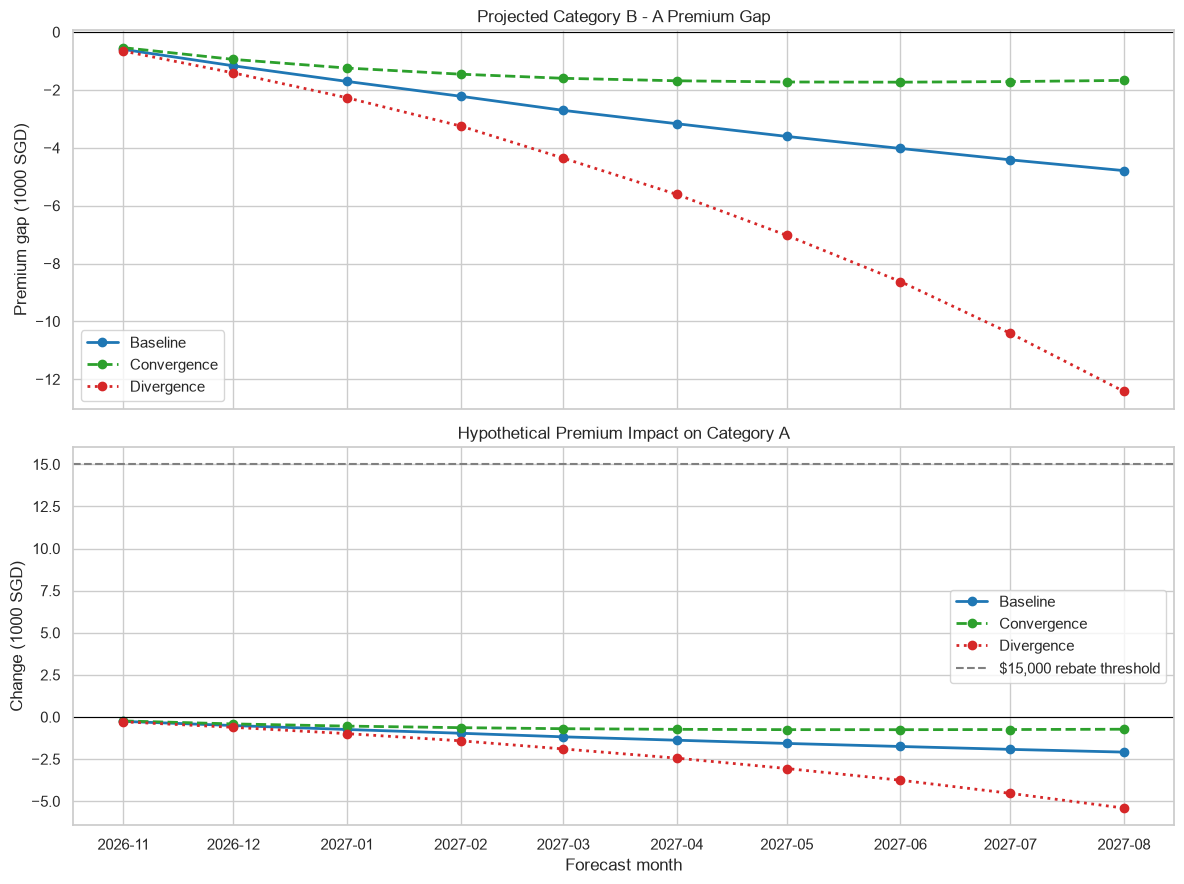

In [56]:

fig, axes = plt.subplots(
    2, 1, figsize=(12, 9), sharex=True
)

colors = {
    "Baseline": "tab:blue",
    "Convergence": "tab:green",
    "Divergence": "tab:red"
}

styles = {
    "Baseline": "-",
    "Convergence": "--",
    "Divergence": ":"
}

for name in ["Baseline", "Convergence", "Divergence"]:

    subset = scenario_df[
        scenario_df["Scenario"] == name
    ].sort_values("Date")

    axes[0].plot(
        subset["Date"],
        subset["Premium gap"],
        marker="o",
        linestyle=styles[name],
        color=colors[name],
        label=name,
        linewidth=2
    )

    axes[1].plot(
        subset["Date"],
        subset["Impact on A"],
        marker="o",
        linestyle=styles[name],
        color=colors[name],
        label=name,
        linewidth=2
    )

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Projected Category B - A Premium Gap")
axes[0].set_ylabel("Premium gap (1000 SGD)")
axes[0].legend()

axes[1].axhline(0, color="black", linewidth=0.8)

axes[1].axhline(
    15,
    color="gray",
    linestyle="--",
    label="$15,000 rebate threshold"
)

axes[1].set_title("Hypothetical Premium Impact on Category A")
axes[1].set_ylabel("Change (1000 SGD)")
axes[1].set_xlabel("Forecast month")
axes[1].legend()

plt.tight_layout()
plt.show()

**Overview**\
Baseline: Use regression forecast without adjustment\
Convergence: Premium gap narrows by 10% per horizon\
Divergence: Premium gap widens by 10% per horizon

**Limitation**\
Due to poor linear regression model fit, predicted values indicate that Cat A and B premiums continue to converge. Eventually, Cat A becomes more expensive than Cat B.

In reality, this is highly unlikely to occur. To correct for this, we created a separate hypothetical simulation where Cat B premiums exceed Cat A premiums.

This allows us to investigate how convergence and divergence affect Cat A buyers when the original premium gap is positive, without depending on our regression forecasts.

> Refer to the Visualisations section for this forecast.

#### 5.2.4 Comparing 3 vs 5 band feebate

In [57]:
# Illustrative fee/rebate schedules, in 1000 SGD
feebate_designs = {
    "Three-band": {
        "Lower OMV": -15,
        "Middle OMV": 0,
        "Higher OMV": 15
    },
    "Five-band": {
        "Lowest OMV": -15,
        "Lower-middle OMV": -7.5,
        "Middle OMV": 0,
        "Upper-middle OMV": 7.5,
        "Highest OMV": 15
    }
}

# Use the latest hypothetical merged premium
merged_reference = merger_df["merged_weighted"].iloc[-1]

feebate_results = []

for design, bands in feebate_designs.items():
    for band, adjustment in bands.items():

        feebate_results.append({
            "Design": design,
            "OMV group": band,
            "Adjustment": adjustment,
            "Effective COE cost": (
                merged_reference + adjustment
            )
        })

feebate_df = pd.DataFrame(feebate_results)

display(feebate_df.round(2))


,Design,OMV group,Adjustment,Effective COE cost
0,Three-band,Lower OMV,-15.0,116.96
1,Three-band,Middle OMV,0.0,131.96
2,Three-band,Higher OMV,15.0,146.96
3,Five-band,Lowest OMV,-15.0,116.96
4,Five-band,Lower-middle OMV,-7.5,124.46
5,Five-band,Middle OMV,0.0,131.96
6,Five-band,Upper-middle OMV,7.5,139.46
7,Five-band,Highest OMV,15.0,146.96


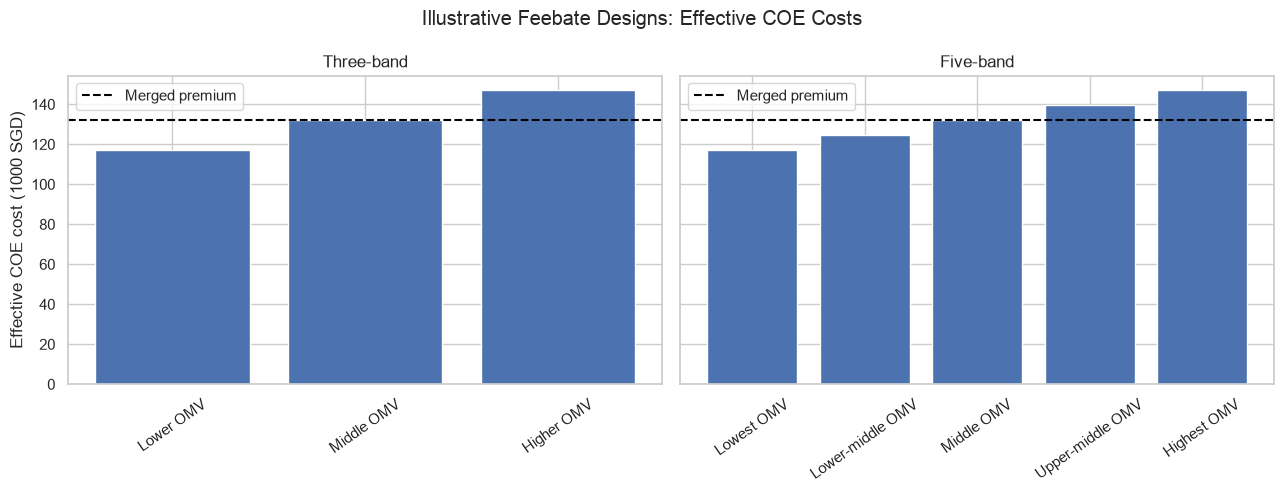

(<Figure size 1300x500 with 2 Axes>,
 array([<Axes: title={'center': 'Three-band'}, ylabel='Effective COE cost (1000 SGD)'>,
        <Axes: title={'center': 'Five-band'}>], dtype=object))

In [58]:

def plot_bands(feebate_df, merged_reference):
    # Create figure
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5), sharey=True
    )

    # Plot each feebate design
    for ax, design in zip(
        axes, ["Three-band", "Five-band"]
    ):
        subset = feebate_df[
            feebate_df["Design"] == design
        ]

        ax.bar(
            subset["OMV group"],
            subset["Effective COE cost"]
        )

        ax.axhline(
            merged_reference,
            color="black",
            linestyle="--",
            label="Merged premium"
        )

        ax.set_title(design)
        ax.tick_params(axis="x", rotation=35)
        ax.legend()

    axes[0].set_ylabel(
        "Effective COE cost (1000 SGD)"
    )

    fig.suptitle(
        "Illustrative Feebate Designs: Effective COE Costs"
    )

    plt.tight_layout()
    plt.show()

    return fig, axes

plot_bands(feebate_df, merged_reference)

#### 5.2.5 Overall Effectiveness

The feebate policy can be evaluated based on 2 metrics; *effectiveness* and *necessity*

1. Effectiveness: whether the feebate covers the increase in Cat A premium from the baseline\
In most cases, both 3 and 5-tier feebates are effective. The proposed rebate value is significantly higher than the required value. Hence, the new policy likely has little negative impact on car buyers.

2. Necessity: whether the feebate benefits society as a whole\
This is largely dependent on the premium gap. During periods with inherenetly narrow premium gaps, little to no feebate is required as the weighted average COE premium is close to the predicted Cat A/B premiums.

In such cases, a 5-tier feebate provides more flexibility as some buyers can be allocated to a lower tier of $7500. This helps to reduce, but not eliminate the unnecessary subsidy of COE premiums. 

## 6. Visualisations

*Instructions:* Generate every chart used in your deck here. Each chart should have a clear title, labelled axes with units, and a one-line takeaway in a markdown cell below it.

In [59]:
# Defined functions to annotate the graphs with significant events and gaps
# Significant COE event dates
event_dates = pd.to_datetime([
    "2014-02-01",
    "2018-02-01",
    "2022-05-01",
    "2022-07-01"
])

# COVID-19 bidding suspension
gap_start = pd.Timestamp("2020-04-01")
gap_end = pd.Timestamp("2020-07-01")

def add_annotations(ax):
    # Red dashed lines for significant events
    for date in event_dates:
        ax.axvline(
            x=date,
            color="red",
            linestyle="--",
            linewidth=1.2,
            alpha=0.7
        )

    # Grey shaded region
    ax.axvspan(
        gap_start, gap_end,
        color="grey",
        alpha=0.2,
        zorder=0
    )

    # Black dotted borders
    for date in [gap_start, gap_end]:
        ax.axvline(
            x=date,
            color="black",
            linestyle=":",
            linewidth=1.5
        )

    ax.grid(alpha=0.3)

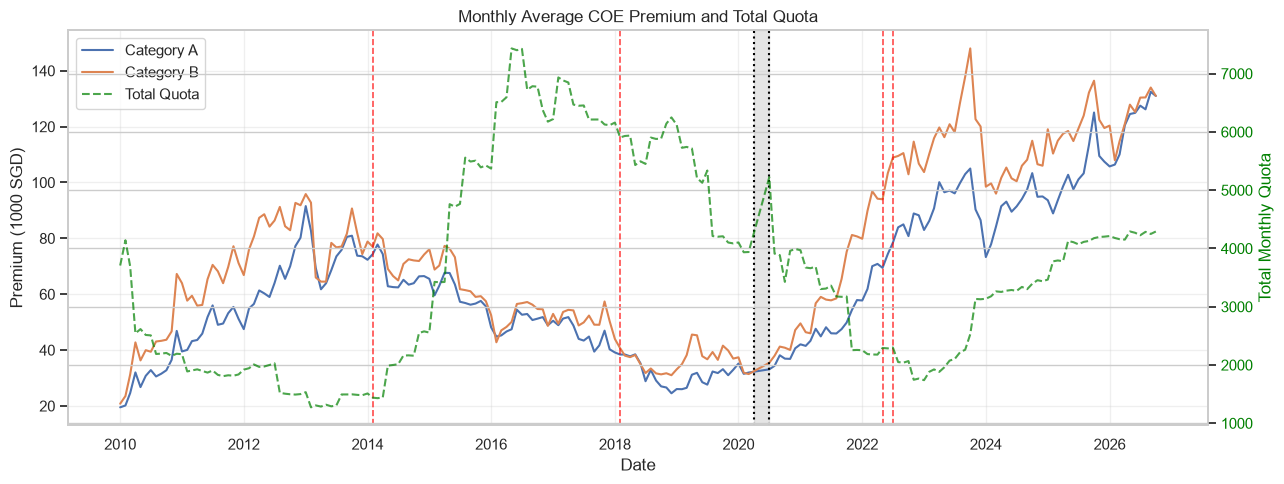

In [60]:
# Calculate total monthly quota for Categories A and B
monthly_quota = (
    coe_ab
    .groupby("date")["quota"]
    .sum()
    .reindex(premium.index)
)

# Preserve the Apr-Jun 2020 gap
monthly_quota.loc["2020-04-01":"2020-06-01"] = float("nan")

fig, ax = plt.subplots(figsize=(13, 5))

# Left axis: COE premiums
ax.plot(
    premium.index,
    premium["Category A"],
    label="Category A"
)

ax.plot(
    premium.index,
    premium["Category B"],
    label="Category B"
)

# Right axis: Total monthly quota
ax2 = ax.twinx()

ax2.plot(
    monthly_quota.index,
    monthly_quota,
    color="green",
    linestyle="--",
    alpha=0.7,
    label="Total Quota"
)

# Existing annotations
add_annotations(ax)

# Labels
ax.set_title("Monthly Average COE Premium and Total Quota")
ax.set_ylabel("Premium (1000 SGD)")
ax.set_xlabel("Date")
ax2.set_ylabel("Total Monthly Quota", color="green")
ax2.tick_params(axis="y", labelcolor="green")

# Combined legend
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

**Takeaway**: Premiums exibit negative correlation with quota.

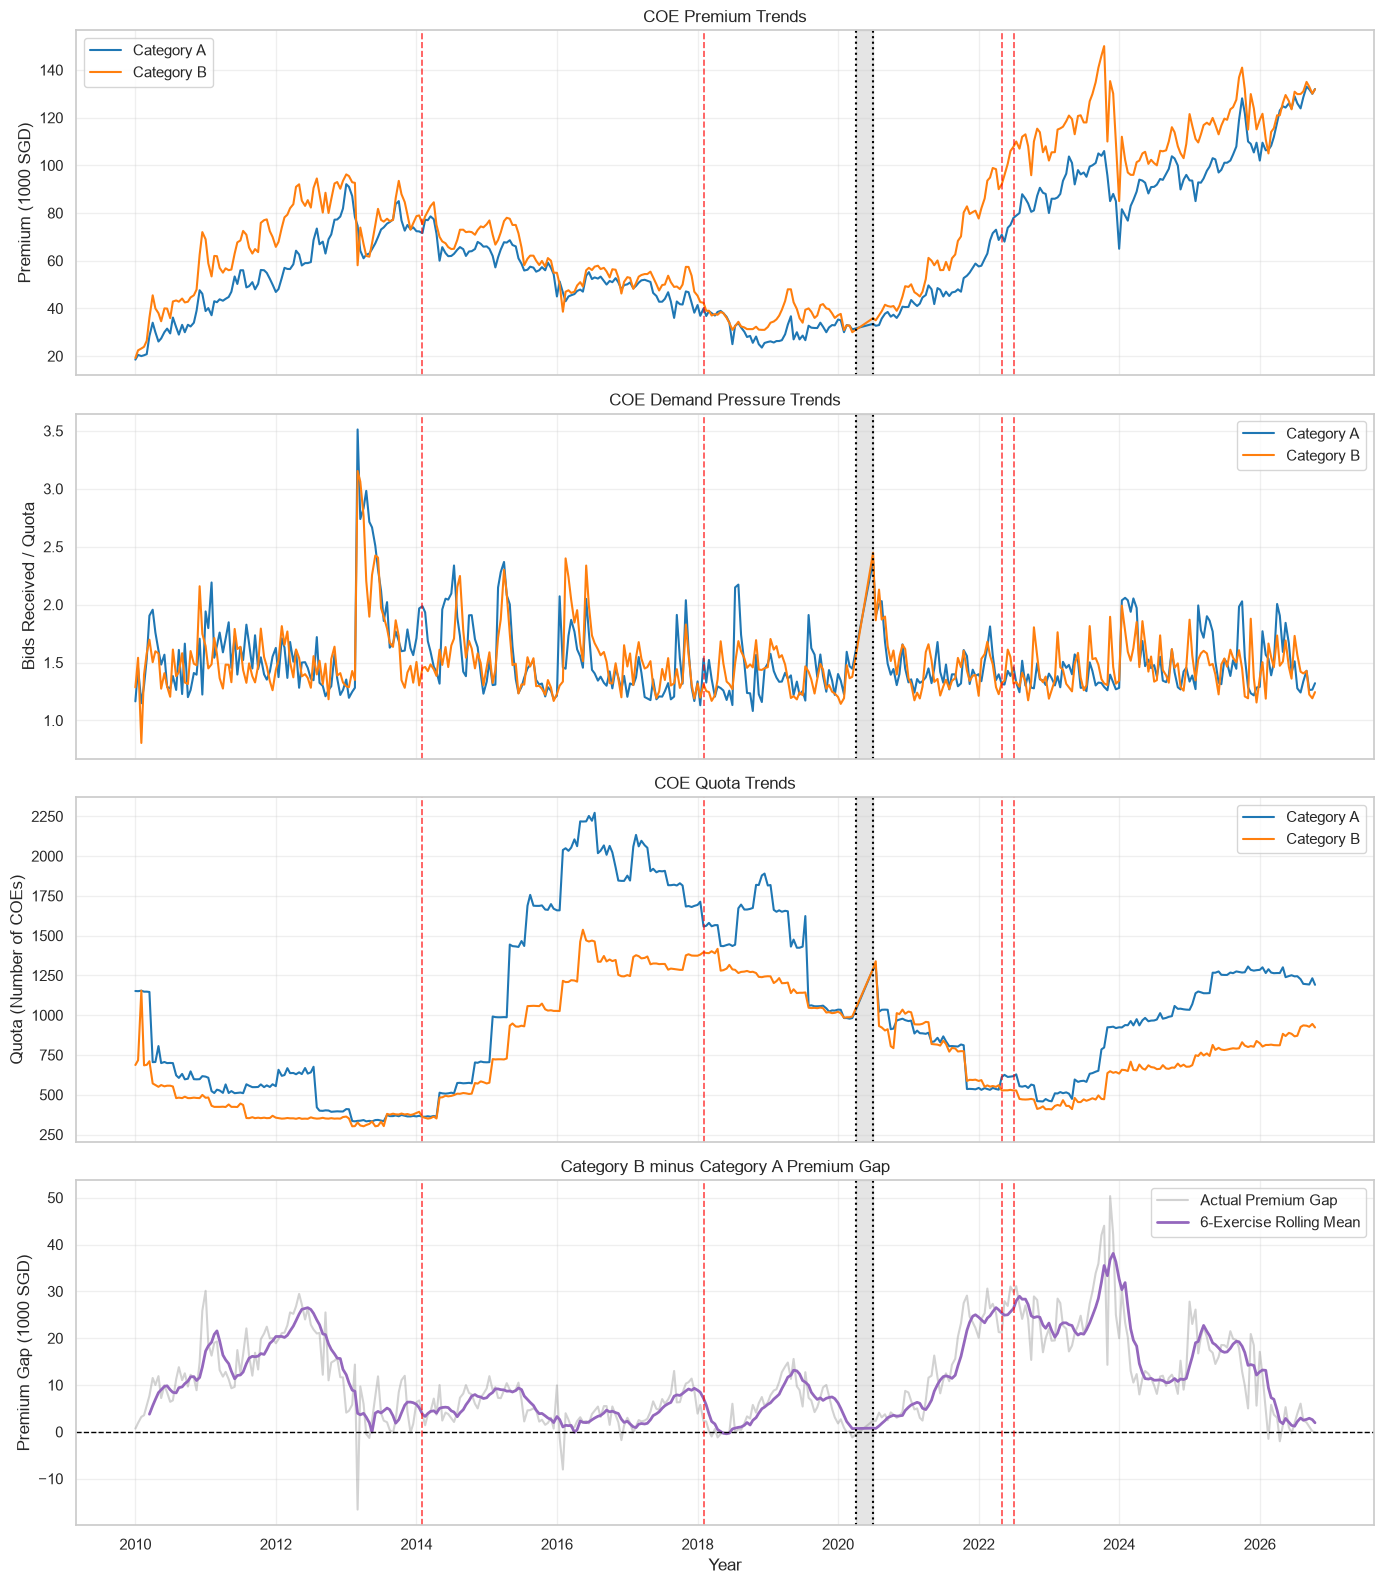

In [61]:
fig, axes = plot_pressure_premium(coe_wide)
plt.show()

**Takeaway**: Decreasing correlation between wide peremium gap and increasing premiums.

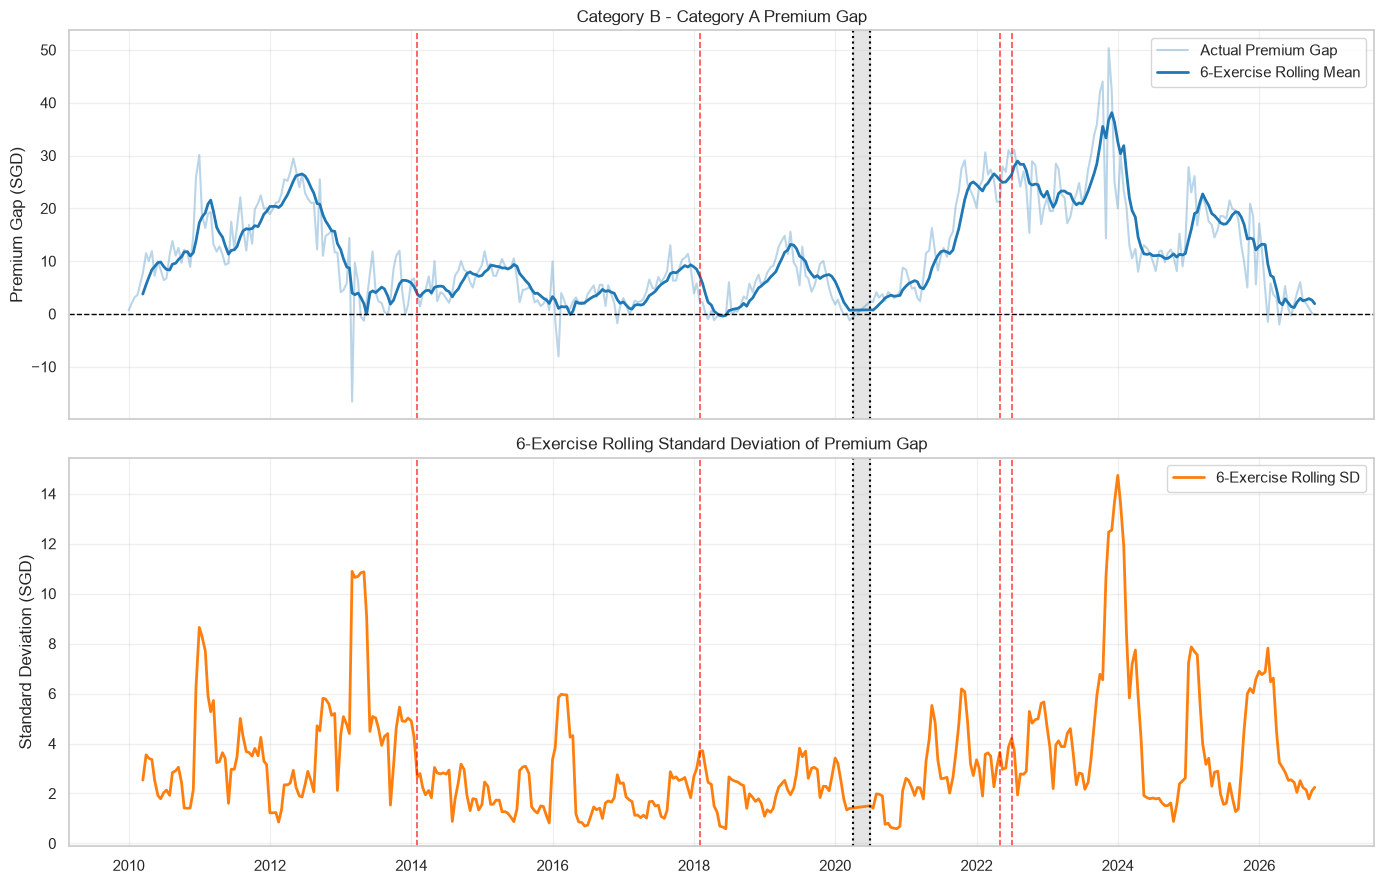

(<Figure size 1400x900 with 2 Axes>,
 array([<Axes: title={'center': 'Category B - Category A Premium Gap'}, ylabel='Premium Gap (SGD)'>,
        <Axes: title={'center': '6-Exercise Rolling Standard Deviation of Premium Gap'}, ylabel='Standard Deviation (SGD)'>],
       dtype=object))

In [62]:
plot_volatility(coe_analysis, window=6)

**Takeaway**: Large premium gaps associated with higher SD. Decreasing SD hints that premium gap is steadily closing.

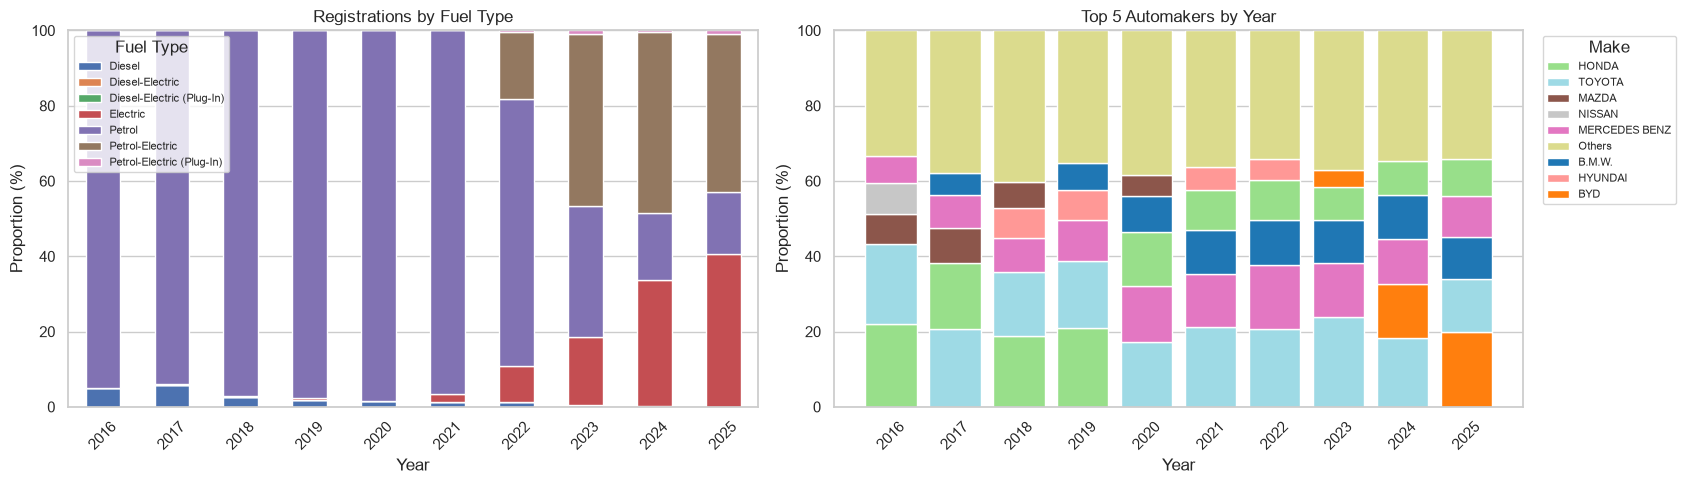

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# 1. Fuel type proportions
fuel_pct = (
    registrations_raw.groupby(["year", "fuel_type"])["number"]
    .sum().unstack(fill_value=0)
)
fuel_pct = fuel_pct.div(fuel_pct.sum(axis=1), axis=0) * 100

fuel_pct.plot(kind="bar", stacked=True, ax=axes[0], legend=False)
axes[0].set(title="Registrations by Fuel Type",
            xlabel="Year", ylabel="Proportion (%)", ylim=(0, 100))
axes[0].legend(title="Fuel Type", loc="upper left", fontsize=8)

# 2. Top 5 automakers by year
make_df = (
    registrations_raw.groupby(["year", "make"], as_index=False)["number"]
    .sum()
)
make_df["rank"] = make_df.groupby("year")["number"].rank(
    method="first", ascending=False
)
make_df["make"] = make_df["make"].where(make_df["rank"] <= 5, "Others")

make_pct = make_df.groupby(["year", "make"])["number"].sum().unstack(fill_value=0)
make_pct = make_pct.div(make_pct.sum(axis=1), axis=0) * 100

colors = dict(zip(
    make_pct.columns,
    plt.cm.tab20(np.linspace(0, 1, len(make_pct.columns)))
))

for i, (_, row) in enumerate(make_pct.iterrows()):
    bottom = 0
    ordered = pd.concat([
        row.drop("Others").sort_values(ascending=False),
        row[["Others"]]
    ])
    for make, pct in ordered.items():
        if pct > 0:
            axes[1].bar(i, pct, bottom=bottom, color=colors[make], label=make)
            bottom += pct

axes[1].set(
    title="Top 5 Automakers by Year",
    xlabel="Year", ylabel="Proportion (%)", ylim=(0, 100)
)
axes[1].set_xticks(range(len(make_pct)))
axes[1].set_xticklabels(make_pct.index, rotation=45)

handles, labels = axes[1].get_legend_handles_labels()
unique = dict(zip(labels, handles))
axes[1].legend(unique.values(), unique.keys(), title="Make",
               bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

axes[0].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


**Takeaway**: Increasing proportion of EVs and hybrids. Rising market share of EV manufacturers.

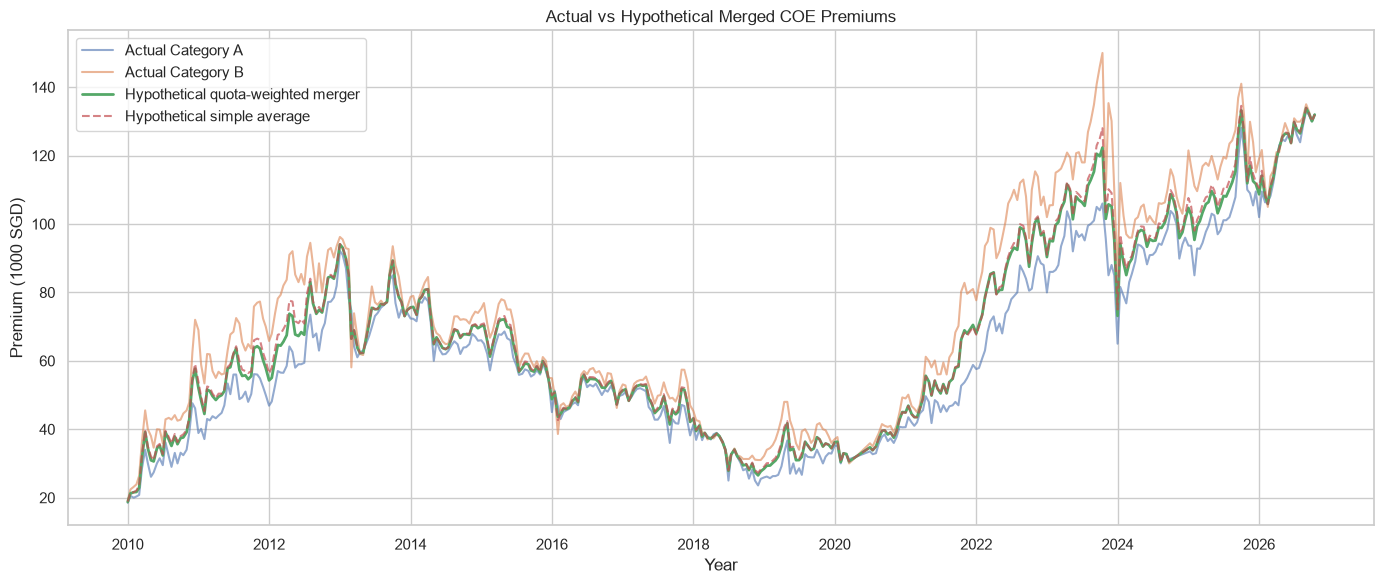

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Actual vs Hypothetical Merged COE Premiums'}, xlabel='Year', ylabel='Premium (1000 SGD)'>)

In [64]:
plot_merged_premiums(merger_df)

**Takeaway**: Graph showing effect of merged premium; largely in between original Cat A/B premiums.

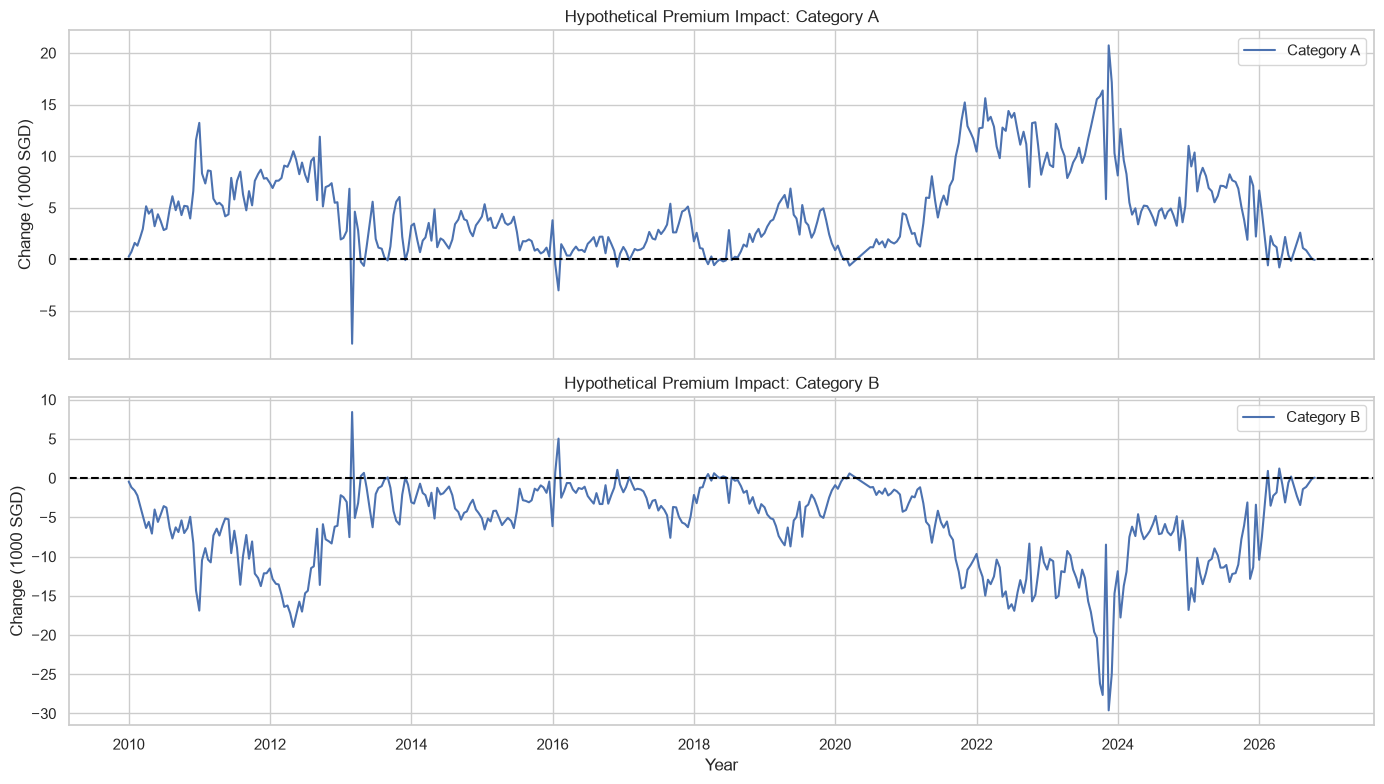

(<Figure size 1400x800 with 2 Axes>,
 array([<Axes: title={'center': 'Hypothetical Premium Impact: Category A'}, ylabel='Change (1000 SGD)'>,
        <Axes: title={'center': 'Hypothetical Premium Impact: Category B'}, xlabel='Year', ylabel='Change (1000 SGD)'>],
       dtype=object))

In [65]:
plot_merger_impact(merger_df)

**Takeaway**: Visualising the gap between price effectes on Cat A and B after the merge.

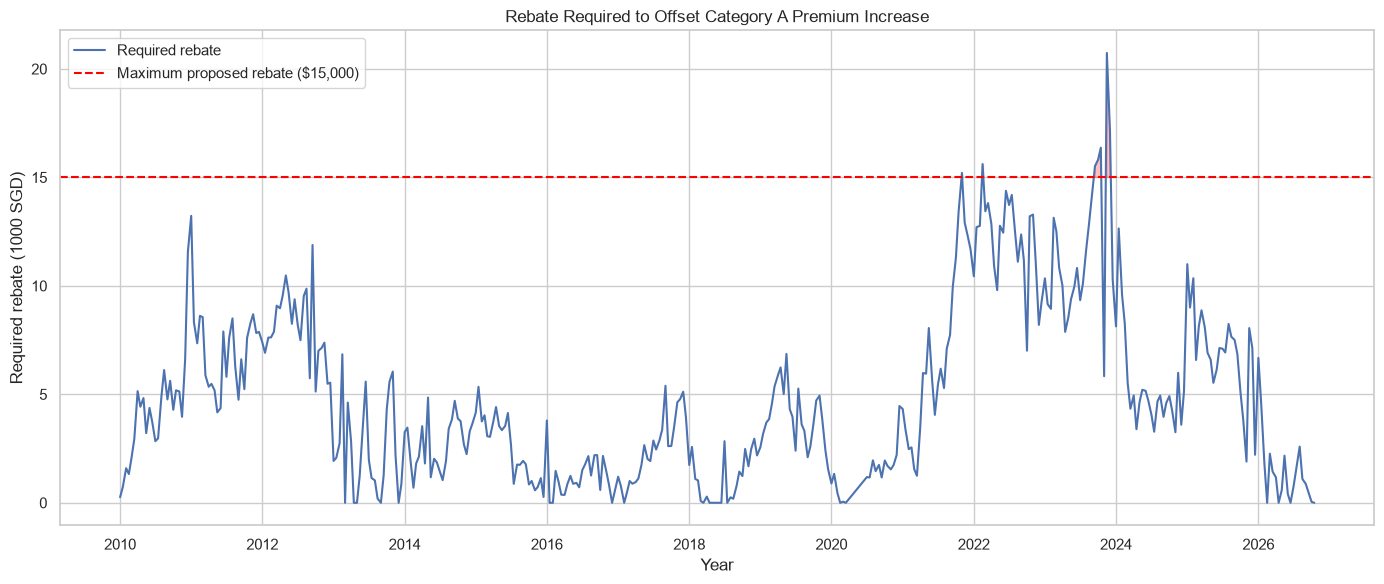

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Rebate Required to Offset Category A Premium Increase'}, xlabel='Year', ylabel='Required rebate (1000 SGD)'>)

In [66]:
plot_max_rebate(merger_df, max_rebate=15.0)

**Takeaway**: Maximum rebate of $15,000 is well in excess of required rebate.

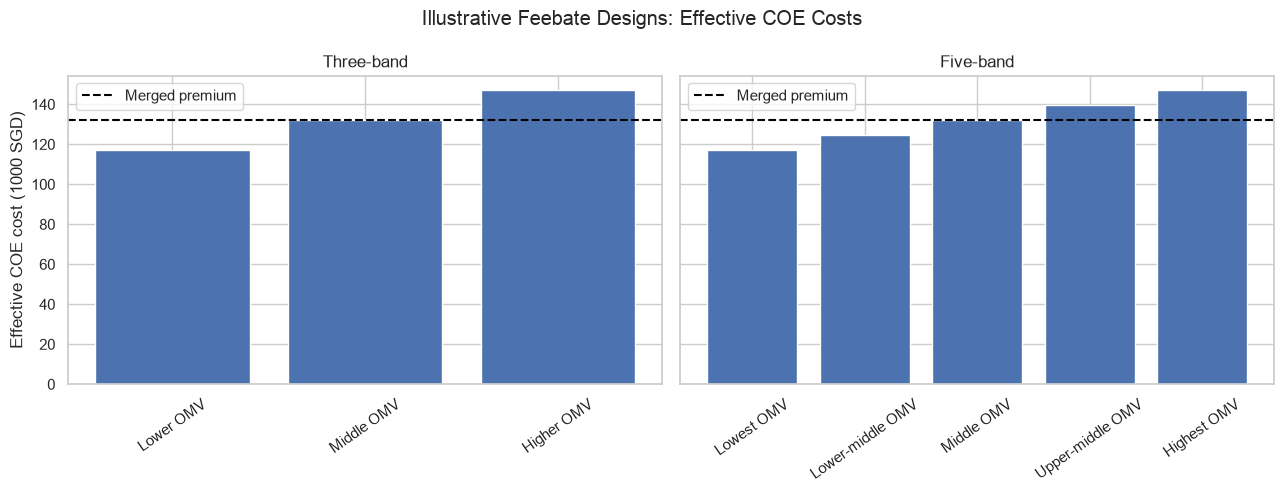

(<Figure size 1300x500 with 2 Axes>,
 array([<Axes: title={'center': 'Three-band'}, ylabel='Effective COE cost (1000 SGD)'>,
        <Axes: title={'center': 'Five-band'}>], dtype=object))

In [67]:
plot_bands(feebate_df, merged_reference)

**Takeaway**: Illustration of effective COE cost after merge, using weighted average premium.

In [68]:

# Hypothetical positive premium gap simulation

HORIZON = 10
MAX_REBATE = 15.0  # 1000 SGD

# Initial assumptions (1000 SGD)
initial_A = 100.0
initial_B = 120.0
share_A = 0.60

initial_gap = initial_B - initial_A

# Quota-weighted reference premium
weighted_centre = (
    share_A * initial_A
    + (1 - share_A) * initial_B
)

scenario_assumptions = {
    "Baseline": 1.00,
    "Convergence": 0.90,
    "Divergence": 1.10
}

hypothetical_results = []

for h in range(HORIZON + 1):

    for name, gap_factor in scenario_assumptions.items():

        adjusted_gap = initial_gap * (gap_factor ** h)

        # Preserve weighted centre
        premium_A = (
            weighted_centre
            - (1 - share_A) * adjusted_gap
        )

        premium_B = (
            weighted_centre
            + share_A * adjusted_gap
        )

        merged = (
            share_A * premium_A
            + (1 - share_A) * premium_B
        )

        impact_A = merged - premium_A

        required_rebate = max(0, impact_A)

        hypothetical_results.append({
            "Period": h,
            "Scenario": name,
            "Premium A": premium_A,
            "Premium B": premium_B,
            "Premium gap": adjusted_gap,
            "Merged premium": merged,
            "Impact on A": impact_A,
            "Required rebate A": required_rebate,
            "Rebate sufficient": required_rebate <= MAX_REBATE
        })

hypothetical_df = pd.DataFrame(hypothetical_results)

display(hypothetical_df.round(2).head(9))


,Period,Scenario,Premium A,Premium B,Premium gap,Merged premium,Impact on A,Required rebate A,Rebate sufficient
0,0,Baseline,100.00,120.00,20.0,108.0,8.00,8.00,True
1,0,Convergence,100.00,120.00,20.0,108.0,8.00,8.00,True
2,0,Divergence,100.00,120.00,20.0,108.0,8.00,8.00,True
3,1,Baseline,100.00,120.00,20.0,108.0,8.00,8.00,True
4,1,Convergence,100.80,118.80,18.0,108.0,7.20,7.20,True
5,1,Divergence,99.20,121.20,22.0,108.0,8.80,8.80,True
6,2,Baseline,100.00,120.00,20.0,108.0,8.00,8.00,True
7,2,Convergence,101.52,117.72,16.2,108.0,6.48,6.48,True
8,2,Divergence,98.32,122.52,24.2,108.0,9.68,9.68,True


**Takeaway**: Data processing for the following chart, calculate premium gap changes.

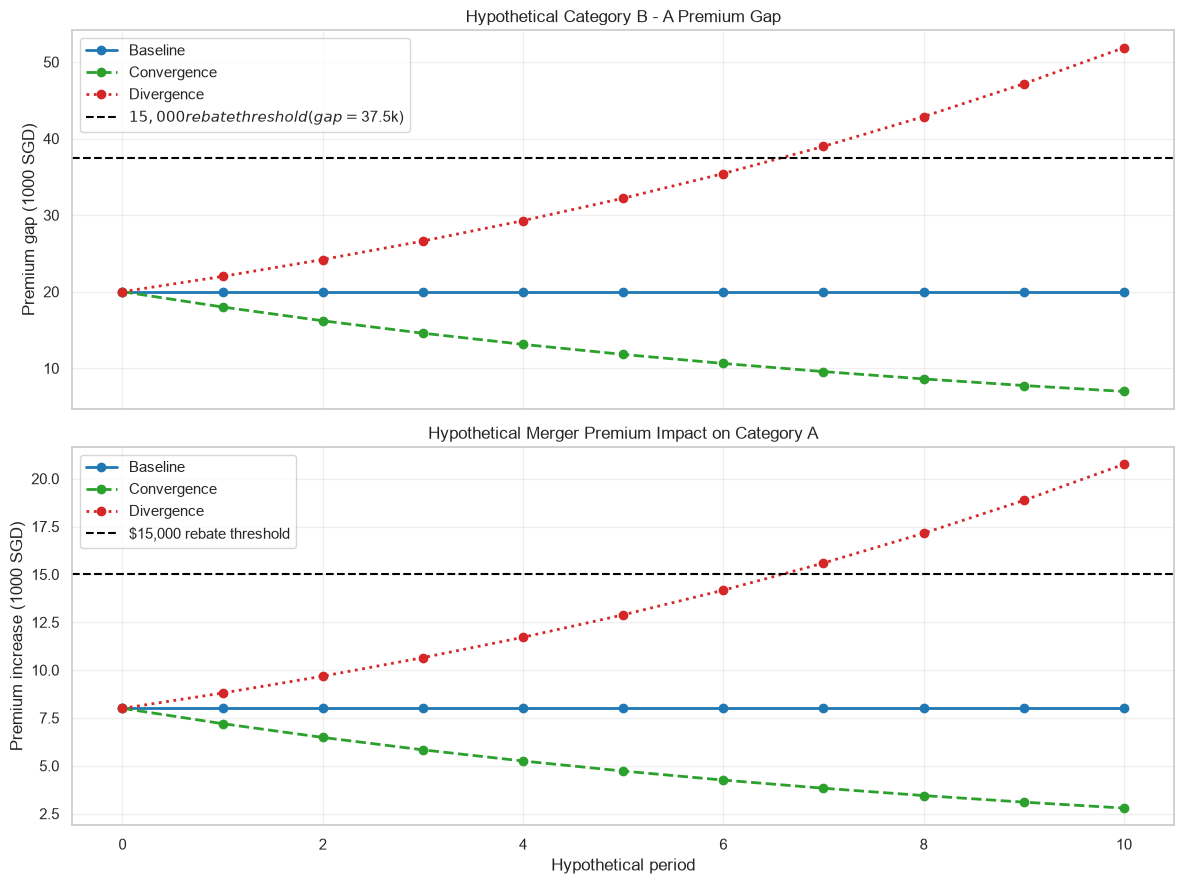

In [69]:

fig, axes = plt.subplots(
    2, 1, figsize=(12, 9), sharex=True
)

colors = {
    "Baseline": "tab:blue",
    "Convergence": "tab:green",
    "Divergence": "tab:red"
}

styles = {
    "Baseline": "-",
    "Convergence": "--",
    "Divergence": ":"
}

for name in ["Baseline", "Convergence", "Divergence"]:

    subset = hypothetical_df[
        hypothetical_df["Scenario"] == name
    ].sort_values("Period")

    axes[0].plot(
        subset["Period"],
        subset["Premium gap"],
        marker="o",
        linestyle=styles[name],
        color=colors[name],
        label=name,
        linewidth=2
    )

    axes[1].plot(
        subset["Period"],
        subset["Impact on A"],
        marker="o",
        linestyle=styles[name],
        color=colors[name],
        label=name,
        linewidth=2
    )

# Premium gap corresponding to the maximum $15,000 rebate
gap_threshold = MAX_REBATE / (1 - share_A)

# First graph: premium gap threshold
axes[0].axhline(
    gap_threshold,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"$15,000 rebate threshold (gap = ${gap_threshold:,.1f}k)"
)

# Second graph: premium increase threshold
axes[1].axhline(
    MAX_REBATE,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="$15,000 rebate threshold"
)

axes[0].set_title(
    "Hypothetical Category B - A Premium Gap"
)
axes[0].set_ylabel("Premium gap (1000 SGD)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title(
    "Hypothetical Merger Premium Impact on Category A"
)
axes[1].set_ylabel("Premium increase (1000 SGD)")
axes[1].set_xlabel("Hypothetical period")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Takeaway**: Illustration of required rebate for 3 scenarios of changing premium gap. Black dotted line indicates maximum rebate and corresponding premium gap.

In [70]:
# Key statistics for the hypothetical premium gap
print(gap_stats.round(2))

mean      11.11
median     9.01
std        9.32
min      -16.60
max       50.34
Name: premium_gap, dtype: float64


In [71]:
# Probability of exceeding the $15,000 rebate threshold (%)
(1 - norm.cdf(37.5, loc=11.11, scale=9.32)) * 100

np.float64(0.23161852707825892)

## 7. Key Findings & Recommendation

*Instructions:* Summarise your main findings and state your recommendation. This should match your deck.

**Recommendation:** Implement a 5-tier feebate system for maximun flexibility. The monetary value of feebates should be based on relative vehicle OMV.

**Key findings:**
1. Increasing EV adoption is correlated with narrowing COE Cat A-B premium gap.
2. $15,000 feebate ceiling is more than adequate most of the time.
3. The amount of necessary feebate experinces significant variation.

## 8. Assumptions & Limitations

**What the data shows:**
- Narrowing premium gaps leads to a decrease in required feebate.

**What we assumed:**
- "Required feebate" is calculated with the difference between Cat A premium and the Cat A & B weighted average premium.
- Cat A/B premiums are only a proxy for the actual OMV of vehicles in each category.
- Feebate bands based on vehicle OMV accurately segregates car buyers based on their relative income level.
- Bands should be updated over time to reflect changing vehicle prices and quality.

**What is speculation:**
- Cat A & B premiums before 2020 accurately reflects the OMV of registered vehicles given the low proportion of EVs and hybrids.
- Significant proportion of newly registered EVs are tuned to meet Cat A specifications.

**Limitations:**
- No data is available to verify the proportion of vehicle types in each COE categoty.
- Forecasts do not account for changes in vehicle OMV over time. Pricing of EVs may differ from that of traditional ICE vehicles.

## 9. Data Sources & Declarations

**Data sources:**
| Dataset | Source (link) | Date downloaded |
| --- | --- | --- |
| COE bidding results | [Provided by SDS] | – |
| Vehicle registrations | [Provided by SDS] | – |
| [Additional dataset, if any] | [Link] | [DD MMM YYYY] |

**AI tool use:** Used ChatGPT for code debugging, formatting and queries on available functions.